# Final risk evaluation and performance

In [2]:
# 1. Enable Auto-reloading
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Add the project root to Python path
project_root = Path.cwd().parent  # Goes up one level from notebooks/
sys.path.insert(0, str(project_root))

# 2. Import your heavy logic from your Python file
from core.gnn_layer.risk_predict import (
    fetch_graph_from_neo4j, 
    RiskEscalationGNN,
    evaluate_with_kfold,
    generate_threat_report,
    graph_edge_oversample,
    train_model
)

from core.kg_sna_layer.graph_builder import(
    calculate_strict_fold_topology
)

from torch_geometric.data import Data

print("Environment linked and modules loaded successfully!")

import torch
import random
import numpy as np
import os

# Lock the random seed for 100% reproducibility
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    #torch.cuda.manual_seed_all(seed) # if you are using multi-GPU

    # Force CUDA to select deterministic algorithms (Disables parallel speed shortcuts)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # If using newer PyTorch Geometric versions, lock down scatter operations
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8' 
    try:
        torch.use_deterministic_algorithms(True)
    except RuntimeError:
        # Fallback for older environments that don't support strict locking
        pass
seed_everything(42)

c:\Users\dhara\anaconda3\envs\sna_oms_thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment linked and modules loaded successfully!


In [5]:
import pandas as pd
import seaborn as sns
from datetime import datetime
from core.config import graph_base
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score
from scipy.ndimage import gaussian_filter1d
from neo4j import GraphDatabase


print("⏳ Fetching Graph from Neo4j...")
data_baseline, data_enriched, reverse_mapping = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)
print(f"✅ Graph Fetched: {data_baseline.x.size(0)} Nodes, {data_baseline.edge_index.size(1)} Edges.")

print("⏳ Scaling Enriched NLP Node Features...")
scaler = StandardScaler()
# We scale the Extremist and Contraband counts so they don't overpower the GNN
scaled_features = scaler.fit_transform(data_enriched.x.numpy())
data_enriched.x = torch.tensor(scaled_features, dtype=torch.float)
print(f"✅ Baseline Node Features: {data_baseline.x.size(1)} (Dummy Variable)")
print(f"✅ Enriched Node Features: {data_enriched.x.size(1)} (Scaled NLP Taxonomy Counts)")

⏳ Fetching Graph from Neo4j...


Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SNA_TIE_STRENGTH` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=4, column=34, offset=106>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 106, 'line': 4, 'column': 34}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        MATCH (a)-[r]->(b) \n        WHERE type(r) <> 'SNA_TIE_STRENGTH'\n        OPTIONAL MATCH (a)-[meta:SNA_TIE_STRENGTH]->(b)\n        RETURN a.name AS source, \n               b.name AS target, \n               r.risk_weight AS weight,\n               type(r) AS rel_type,  \n       

✅ Graph Fetched: 740 Nodes, 2173 Edges.
⏳ Scaling Enriched NLP Node Features...
✅ Baseline Node Features: 1 (Dummy Variable)
✅ Enriched Node Features: 1 (Scaled NLP Taxonomy Counts)


## Data distribution features

In [6]:
def plot_dynamic_feature_distributions(data_baseline):
    print("⏳ Simulating a safe training fold to extract leak-proof features...")

    # 1. Simulate a single 80/20 train split (Stratified by class)
    indices = np.arange(data_baseline.edge_index.size(1))
    y_array = data_baseline.y.numpy().flatten()
    train_idx, _ = train_test_split(indices, test_size=0.2, stratify=y_array, random_state=42)

    train_edge_index = data_baseline.edge_index[:, train_idx]

    train_edge_weights = data_baseline.edge_weight[train_idx]


    num_nodes = data_baseline.x.size(0)

    # 2. Calculate the 6 dynamic features safely!
    # Returns: [CN, Jaccard, Betw(src), Betw(tgt), Eigen(src), Eigen(tgt)]
    train_edge_attr = calculate_strict_fold_topology(train_edge_index, train_edge_index, num_nodes, train_edge_weights )

    # 3. Convert the PyTorch tensor into a Pandas DataFrame for easy plotting
    feature_names = [
        'Common Neighbors', 
        'Jaccard Index', 
        'Source Betweenness', 
        'Target Betweenness', 
        'Source Eigenvector', 
        'Target Eigenvector',
        'Aggressiveness',
        'Reputation'
    ]
    df_features = pd.DataFrame(train_edge_attr.numpy(), columns=feature_names)

    # 4. Set up the Academic Aesthetic (Matching your provided image)
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 4, figsize=(20, 12))
    fig.suptitle('Continuous Data Distribution of Input SNA Metrics (Post-Split Training Data)', 
                 fontsize=18, fontweight='bold', y=0.98)

    axes = axes.flatten()

    # Professional Purple Color
    plot_color = '#a37bc4' 
    line_color = '#6a0dad'

    # 5. Loop through and plot all 6 features (now 8)
    for i, col in enumerate(feature_names):
        ax = axes[i]

        # We use a custom KDE line color and histogram bar color to match your aesthetic
        sns.histplot(df_features[col], kde=True, ax=ax, color=plot_color, 
                     edgecolor='white', bins=30, alpha=0.8, line_kws={'color': line_color})

        ax.set_title(f'Distribution: {col}', fontsize=14, pad=10)
        ax.set_xlabel('Score', fontsize=12)
        ax.set_ylabel('Frequency (Edges)', fontsize=12)

    plt.tight_layout(pad=3.0)

    return fig

## Baseline Reality

## Model convergence

In [7]:
def smooth_curve(points, factor=0.85):
    """
    Applies Exponential Moving Average (EMA) to smooth out training noise.
    """
    smoothed_points = []
    for point in points:
        if smoothed_points:
            previous = smoothed_points[-1]
            smoothed_points.append(previous * factor + point * (1 - factor))
        else:
            smoothed_points.append(point)
    return smoothed_points

def plot_model_convergence(all_histories, title="GNN Model Convergence (Averaged across K-Folds)"):
    """
    Plots the Averaged Loss and Accuracy convergence across all K-Folds, 
    applying EMA smoothing while keeping raw data faintly visible.
    """
    epochs = len(all_histories[0]['loss'])

    # 1. Average the metrics across all 5 folds
    raw_loss = np.mean([h['loss'] for h in all_histories], axis=0)
    raw_acc = np.mean([h['acc'] for h in all_histories], axis=0)

    # 2. Apply Smoothing
    smoothed_loss = smooth_curve(raw_loss, factor=0.85)
    smoothed_acc = smooth_curve(raw_acc, factor=0.85)

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # --- Plot Loss on primary Y-axis (Green) ---
    color_loss = '#2ca02c'
    ax1.set_xlabel('Training Epochs', fontsize=12, fontweight='bold')
    ax1.set_ylabel('BCE Loss', color=color_loss, fontsize=12, fontweight='bold')

    # Faint raw data
    ax1.plot(range(1, epochs + 1), raw_loss, color=color_loss, alpha=0.2, linewidth=1.5)
    # Bold smoothed trend
    line1 = ax1.plot(range(1, epochs + 1), smoothed_loss, color=color_loss, linewidth=2.5, label='Training Loss (Smoothed)')
    ax1.tick_params(axis='y', labelcolor=color_loss)

    ax1.grid(True, linestyle='--', alpha=0.4, color='gray')

    # --- Plot Accuracy on secondary Y-axis (Blue) ---
    ax2 = ax1.twinx()  
    color_acc = '#808080' # Professional muted blue
    ax2.set_ylabel('Accuracy', color=color_acc, fontsize=12, fontweight='bold')

    # Faint raw data
    ax2.plot(range(1, epochs + 1), raw_acc, color=color_acc, alpha=0.2, linewidth=1.5)
    # Bold smoothed trend
    line2 = ax2.plot(range(1, epochs + 1), smoothed_acc, color=color_acc, linewidth=2.5, linestyle='-', label='Training Accuracy (Smoothed)')
    ax2.tick_params(axis='y', labelcolor=color_acc)

    # --- Formatting ---
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right', framealpha=0.9, fontsize=11)

    plt.title(title, fontsize=15, pad=20, fontweight='bold')
    fig.tight_layout()

    return fig

## Threshold calibration

In [8]:
def plot_threshold_calibration(y_true, y_probs):
    """
    Plots Precision, Recall, and F1-Score across all thresholds to find the optimal decision boundary.
    """
    # 1. Calculate metrics at various thresholds
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)

    # Calculate F1 Score safely (avoiding division by zero)
    f1_scores = np.divide(
        2 * (precisions[:-1] * recalls[:-1]),
        (precisions[:-1] + recalls[:-1]),
        out=np.zeros_like(precisions[:-1]),
        where=(precisions[:-1] + recalls[:-1]) != 0
    )

    # 2. Find the Optimal Threshold (Maximizing F1)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    optimal_f1 = f1_scores[optimal_idx]

    # 3. Set up the plot aesthetic
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(10, 6))

    # 4. Plot the curves
    ax.plot(thresholds, precisions[:-1], '--', color='tab:blue', label='Precision', linewidth=2)
    ax.plot(thresholds, recalls[:-1], '--', color='tab:orange', label='Recall', linewidth=2)
    ax.plot(thresholds, f1_scores, '-', color='tab:green', label='F1-Score', linewidth=3.5)

    # 5. Plot the Optimal Threshold Line
    ax.axvline(optimal_threshold, color='red', linestyle=':', linewidth=2.5, 
               label=f'Optimal Threshold ({optimal_threshold:.3f})')

    ax.set_title('Threshold Calibration: Precision-Recall Tradeoff', fontsize=16, pad=15, fontweight='bold')
    ax.set_xlabel('Classification Threshold', fontsize=13)
    ax.set_ylabel('Score', fontsize=13)
    ax.set_xlim([-0.05, 1.05])
    ax.set_ylim([-0.05, 1.05])

    ax.legend(loc='lower center', fontsize=12, framealpha=0.9)
    plt.tight_layout()


    print(f"✅ Optimal Threshold Found: {optimal_threshold:.3f} (F1: {optimal_f1:.3f})")
    return fig, optimal_threshold

## Final evaluation curves

In [9]:
def plot_final_evaluation_curves(y_true, y_probs, optimal_threshold):
    """
    Generates side-by-side ROC and Precision-Recall Curves using the global OOF predictions.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    sns.set_theme(style="whitegrid")

    # ==========================================
    # CHART 1: ROC CURVE
    # ==========================================
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)

    ax1.plot(fpr, tpr, color='#2ca02c', linewidth=3.5, label=f'OOF ROC Curve (AUC = {roc_auc:.2f})')
    ax1.plot([0, 1], [0, 1], 'r:', linewidth=2, label='Random Guess')

    # Add a marker for where our Optimal Threshold sits on the ROC curve
    opt_fpr, opt_tpr, _ = roc_curve(y_true, y_probs >= optimal_threshold)
    ax1.plot(opt_fpr[1], opt_tpr[1], marker='o', markersize=10, color='red', 
             label=f'Threshold ({optimal_threshold:.3f})')

    ax1.set_title('Global Out-Of-Fold ROC Curve', fontsize=16, fontweight='bold', pad=15)
    ax1.set_xlabel('False Positive Rate', fontsize=13)
    ax1.set_ylabel('True Positive Rate (Recall)', fontsize=13)
    ax1.legend(loc='lower right', fontsize=12, framealpha=0.9)
    ax1.set_xlim([-0.05, 1.05])
    ax1.set_ylim([-0.05, 1.05])

    # ==========================================
    # CHART 2: PRECISION-RECALL (PR) CURVE
    # ==========================================
    precisions, recalls, _ = precision_recall_curve(y_true, y_probs)
    pr_auc = average_precision_score(y_true, y_probs)
    baseline_pr = np.mean(y_true) # The ratio of actual violent edges

    ax2.plot(recalls, precisions, color='#9467bd', linewidth=3.5, label=f'OOF PR Curve (AP = {pr_auc:.2f})')
    ax2.axhline(baseline_pr, color='red', linestyle=':', linewidth=2, 
                label=f'Random Guess (Baseline PR = {baseline_pr:.2f})')

    # Add a marker for where our Optimal Threshold sits on the PR curve
    opt_p, opt_r, _ = precision_recall_curve(y_true, y_probs >= optimal_threshold)
    # The optimal point is usually the second item in these specific arrays
    ax2.plot(opt_r[1], opt_p[1], marker='o', markersize=10, color='red', 
             label=f'Threshold ({optimal_threshold:.3f})')

    ax2.set_title('Global Out-Of-Fold PR Curve', fontsize=16, fontweight='bold', pad=15)
    ax2.set_xlabel('Recall (How many actual threats did we catch?)', fontsize=13)
    ax2.set_ylabel('Precision (When we alert, how often are we right?)', fontsize=13)
    ax2.legend(loc='upper right', fontsize=12, framealpha=0.9)
    ax2.set_xlim([-0.05, 1.05])
    ax2.set_ylim([-0.05, 1.05])

    plt.tight_layout(pad=3.0)

    return fig

Step 1: Fetching raw metadata distributions from Neo4j...


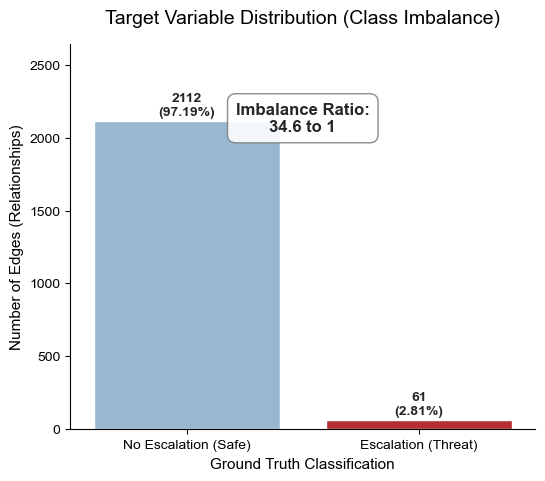

In [10]:
def fetch_raw_class_counts(uri, user, password):
    """
    Fetches the raw count of positive (escalation) vs negative edges 
    by reading the semantic relationship types, ignoring SNA meta-edges.
    """
    query = """
    MATCH ()-[r]->()
    // 1. Filter out the meta-edges generated by the SNA graph_builder
    WHERE type(r) <> 'SNA_TIE_STRENGTH'
    RETURN 
        // 2. Classify based on your actual OMS ontology from schemas.py
        CASE WHEN type(r) IN ['ASSAULTS', 'THREATENS', 'SELF_HARM'] THEN 'Escalation (Class 1)' 
             ELSE 'Baseline (Class 0)' END as Class,
        count(r) as Count
    """
    
    with GraphDatabase.driver(uri, auth=(user, password)) as driver:
        with driver.session() as session:
            result = session.run(query)
            df = pd.DataFrame([dict(record) for record in result])
            
    if df.empty:
        df = pd.DataFrame({'Class': ['Baseline (Class 0)', 'Escalation (Class 1)'], 'Count': [0, 0]})
    return df

def plot_class_imbalance(df_counts):
    """
    Generates a clean bar chart showing the extreme class imbalance.
    """
    fig, ax = plt.subplots(figsize=(6, 5))
    
    sns.set_theme(style="whitegrid")
    
    # ==========================================
    # THE FIX: Map the raw Cypher labels to clean Display labels safely
    # ==========================================
    label_mapping = {
        'Baseline (Class 0)': 'No Escalation (Safe)',
        'Escalation (Class 1)': 'Escalation (Threat)'
    }
    df_counts['Display_Class'] = df_counts['Class'].map(label_mapping)
    
    # Update the barplot to use the new 'Display_Class' column. 
    # Adding 'order' guarantees the Safe (Blue) bar is always on the left!
    sns.barplot(
        x='Display_Class', 
        y='Count', 
        data=df_counts, 
        palette=['#8ebad9', '#cb181d'], 
        ax=ax, 
        hue='Display_Class', 
        legend=False,
        order=['No Escalation (Safe)', 'Escalation (Threat)'] 
    )
    # ==========================================
    
    # Annotate bars with exact counts and percentages
    total = df_counts['Count'].sum()
    for p in ax.patches:
        height = p.get_height()
        # Prevent division by zero if the dataframe is empty
        percentage = (height / total) * 100 if total > 0 else 0
        ax.text(p.get_x() + p.get_width()/2., height + (total * 0.01),
                f'{int(height)}\n({percentage:.2f}%)',
                ha="center", va="bottom", fontsize=10, fontweight='bold')
    
    # Safely extract the counts based on the exact string labels from our Cypher query
    safe_count = df_counts.loc[df_counts['Class'] == 'Baseline (Class 0)', 'Count'].sum()
    threat_count = df_counts.loc[df_counts['Class'] == 'Escalation (Class 1)', 'Count'].sum()
    
    imbalance_ratio = safe_count / threat_count if threat_count > 0 else 0
    textstr = f'Imbalance Ratio:\n{imbalance_ratio:.1f} to 1'
    
    # Add the text box in the upper center of the plot
    ax.text(0.5, 0.85, textstr, transform=ax.transAxes, fontsize=12,
             verticalalignment='top', horizontalalignment='center', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.9))
    
    # Dynamically scale the y-axis so the text box doesn't overlap the bars
    max_count = df_counts['Count'].max()
    ax.set_ylim(0, max_count * 1.25)
                
    ax.set_title("Target Variable Distribution (Class Imbalance)", fontsize=14, pad=15)
    ax.set_xlabel("Ground Truth Classification", fontsize=11)
    ax.set_ylabel("Number of Edges (Relationships)", fontsize=11)

    sns.despine()
    return fig


print("Step 1: Fetching raw metadata distributions from Neo4j...")
df_class = fetch_raw_class_counts(graph_base.URL, graph_base.USER, graph_base.PASS)
# Generate and display Class Imbalance
fig_imbalance = plot_class_imbalance(df_class)
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_class_imbalance.png", dpi=300, bbox_inches='tight')
plt.show()

Step 2: Rendering Data Quality and Imbalance Visualizations...
✅ Cleaned Data perfectly aligned with GNN Ground Truth:
                                         Category  Frequency
0           Level 1: NEUTRAL/EMOTIONAL (Baseline)       2005
1             Level 2: VIOLATED_SCALED (Baseline)          4
2                        Level 3: HATE (Baseline)         82
3  Level 4 & 5: THREAT / EXTREMIST (Target ≥ 3.8)         82


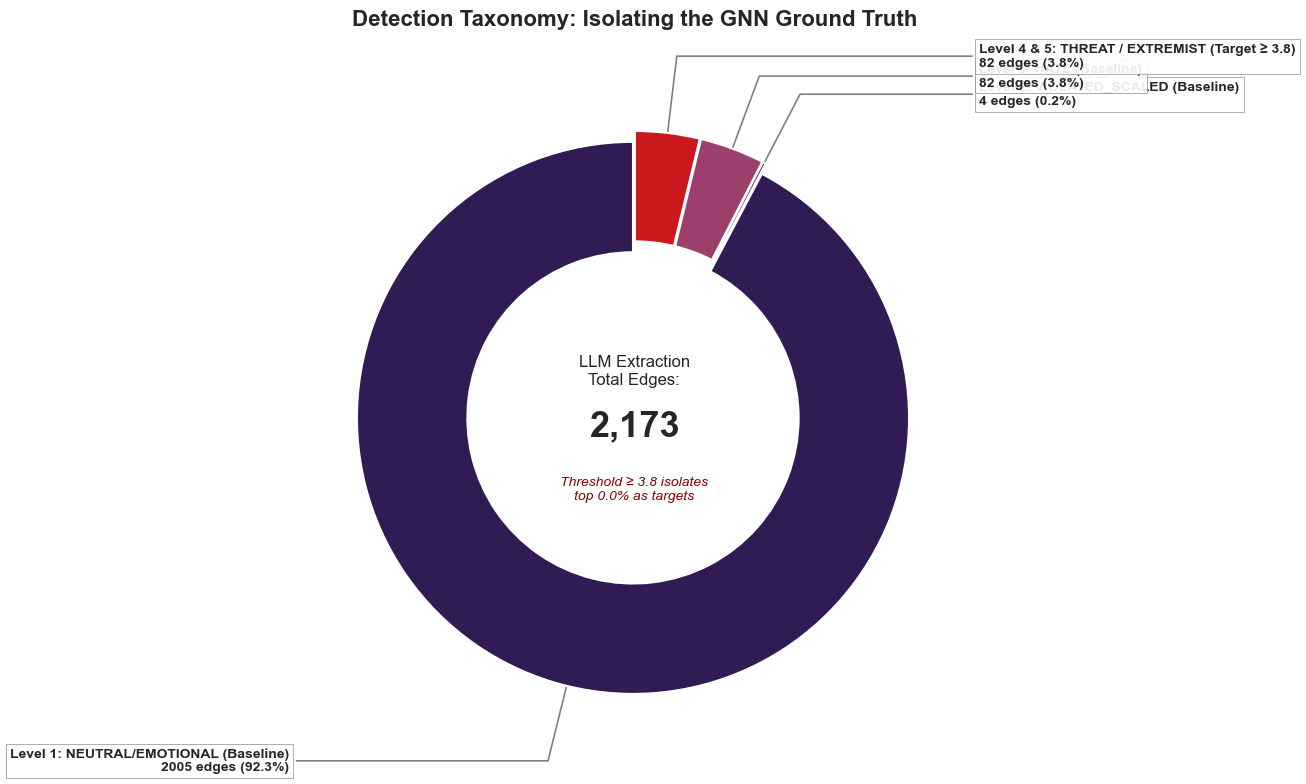

In [11]:
def fetch_taxonomy_distribution(uri, user, password):
    # 1. We capitalize the aliases directly in Cypher. 
    # Neo4j will hand them to Pandas already perfectly named.
    query = """
    MATCH ()-[r]->()
    WHERE type(r) <> 'SNA_TIE_STRENGTH' AND r.risk_weight IS NOT NULL
    RETURN r.risk_weight AS Severity, count(r) AS Frequency
    """

    with GraphDatabase.driver(uri, auth=(user, password)) as driver:
        with driver.session() as session:
            result = session.run(query)

            # THE FIX: dict(record) automatically extracts exactly what the query returned.
            # No manual list comprehensions, no KeyErrors.
            df = pd.DataFrame([dict(record) for record in result])

    if df.empty:
        print("No taxonomy weights found! Check your database.")
        return df

    # 2. Data Cleaning
    df['Severity'] = pd.to_numeric(df['Severity'], errors='coerce')

    # ------------------------------------------------====================
    # NEW GROUND TRUTH MAPPING: Group explicitly by your GNN target rules
    # ------------------------------------------------====================
    def map_to_gnn_class(sev):
        if sev >= 3.8:
            return "Level 4 & 5: THREAT / EXTREMIST (Target ≥ 3.8)"
        elif sev >= 2.1: # Catch Level 3s that dropped into the 2.x range
            return "Level 3: HATE (Baseline)"
        elif sev >= 1.1: # Catch Level 2s that dropped into the 1.x range
            return "Level 2: VIOLATED_SCALED (Baseline)"
        else:
            return "Level 1: NEUTRAL/EMOTIONAL (Baseline)"

    df['Category'] = df['Severity'].apply(map_to_gnn_class)

    df = df.groupby('Category').agg(Frequency=('Frequency', 'sum')).reset_index()

    # Restore the sort order with the new nomenclature
    sort_order = {
        "Level 1: NEUTRAL/EMOTIONAL (Baseline)": 1,
        "Level 2: VIOLATED_SCALED (Baseline)": 2,
        "Level 3: HATE (Baseline)": 3,
        "Level 4 & 5: THREAT / EXTREMIST (Target ≥ 3.8)": 4
    }
    df['Sort'] = df['Category'].map(sort_order)
    df = df.sort_values('Sort').drop(columns=['Sort'])

    print("✅ Cleaned Data perfectly aligned with GNN Ground Truth:")
    print(df) 

    return df

def plot_taxonomy_donut(df):
    """
    Generates an accurate donut chart reflecting the true GNN threshold matrix.
    """
    if df.empty:
        return None

    fig, ax = plt.subplots(figsize=(11, 8), subplot_kw=dict(aspect="equal"))

    labels = df['Category'].tolist()
    sizes = df['Frequency'].tolist()
    total_edges = sum(sizes)

    # Update color map to support your new target category
    color_map = {
        "Level 1: NEUTRAL/EMOTIONAL (Baseline)": '#311b54', 
        "Level 2: VIOLATED_SCALED (Baseline)": '#5b2a6b', 
        "Level 3: HATE (Baseline)": '#9c3f6c', 
        "Level 4 & 5: THREAT / EXTREMIST (Target ≥ 3.8)": '#cb181d' # Target Red
    }
    colors = [color_map[lbl] for lbl in labels]

    # Explode only the true escalation slice out from the rest of the circle
    explode = [0.15 if "Severity" in lbl else 0.02 for lbl in labels]

    wedges, _ = ax.pie(
        sizes, 
        explode=explode, 
        colors=colors,
        startangle=90, 
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=1.5)
    )

    bbox_props = dict(boxstyle="square,pad=0.3", fc="white", ec="gray", lw=0.5, alpha=0.9)
    kw = dict(arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
              bbox=bbox_props, zorder=0, va="center", fontsize=10, fontweight='bold')

    for i, p in enumerate(wedges):
        ang = (p.theta2 - p.theta1) / 2. + p.theta1
        y = np.sin(np.deg2rad(ang))
        x = np.cos(np.deg2rad(ang))

        horizontalalignment = {-1: "right", 1: "left"}[int(np.sign(x))]
        connectionstyle = f"angle,angleA=0,angleB={ang}"
        kw["arrowprops"].update({"connectionstyle": connectionstyle})

        percentage = (sizes[i] / total_edges) * 100
        label_text = f"{labels[i]}\n{sizes[i]} edges ({percentage:.1f}%)"

        offset = 1.45 if "Severity" in labels[i] else 1.25
        ax.annotate(label_text, xy=(x, y), xytext=(offset*np.sign(x), 1.3*y),
                    horizontalalignment=horizontalalignment, **kw)

    # Calculate the exact threat metrics matching your data distribution
    threat_edges = df[df['Category'].str.contains("Severity")]['Frequency'].sum()
    threat_pct = (threat_edges / total_edges) * 100 if total_edges > 0 else 0

    ax.text(0, 0.15, "LLM Extraction\nTotal Edges:", ha='center', va='center', fontsize=12)
    ax.text(0, -0.05, f"{total_edges:,}", ha='center', va='center', fontsize=26, fontweight='bold')
    ax.text(0, -0.28, f"Threshold ≥ 3.8 isolates\ntop {threat_pct:.1f}% as targets", 
             ha='center', va='center', fontsize=10, color='darkred', fontstyle='italic')

    ax.set_title("Detection Taxonomy: Isolating the GNN Ground Truth", fontsize=16, pad=30, fontweight='bold')
    


    return fig

print("Step 2: Rendering Data Quality and Imbalance Visualizations...")
df_tax = fetch_taxonomy_distribution(graph_base.URL, graph_base.USER, graph_base.PASS)

# Generate and display Taxonomy Donut Chart
fig_donut = plot_taxonomy_donut(df_tax)
plt.tight_layout()
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_taxonomy_exploded_donut.png", dpi=300, bbox_inches='tight')
plt.show()

 CHAPTER 1: EVALUATING THE BASELINE MODEL 
Epoch 000 | Loss: 0.0523 | Acc: 0.5000
Epoch 020 | Loss: 0.0421 | Acc: 0.5861
Epoch 040 | Loss: 0.0405 | Acc: 0.6968
Epoch 060 | Loss: 0.0395 | Acc: 0.6854
Epoch 080 | Loss: 0.0387 | Acc: 0.6854
Epoch 100 | Loss: 0.0380 | Acc: 0.6923
Epoch 120 | Loss: 0.0374 | Acc: 0.6944
Epoch 140 | Loss: 0.0369 | Acc: 0.6992
Epoch 000 | Loss: 0.0481 | Acc: 0.4961
Epoch 020 | Loss: 0.0431 | Acc: 0.5448
Epoch 040 | Loss: 0.0421 | Acc: 0.5900
Epoch 060 | Loss: 0.0412 | Acc: 0.6348
Epoch 080 | Loss: 0.0405 | Acc: 0.6461
Epoch 100 | Loss: 0.0399 | Acc: 0.6826
Epoch 120 | Loss: 0.0393 | Acc: 0.6686
Epoch 140 | Loss: 0.0388 | Acc: 0.6698
Epoch 000 | Loss: 0.0448 | Acc: 0.4934
Epoch 020 | Loss: 0.0423 | Acc: 0.5711
Epoch 040 | Loss: 0.0414 | Acc: 0.6671
Epoch 060 | Loss: 0.0405 | Acc: 0.6515
Epoch 080 | Loss: 0.0398 | Acc: 0.6739
Epoch 100 | Loss: 0.0392 | Acc: 0.6695
Epoch 120 | Loss: 0.0387 | Acc: 0.6647
Epoch 140 | Loss: 0.0383 | Acc: 0.6760
Epoch 000 | Loss: 0.0

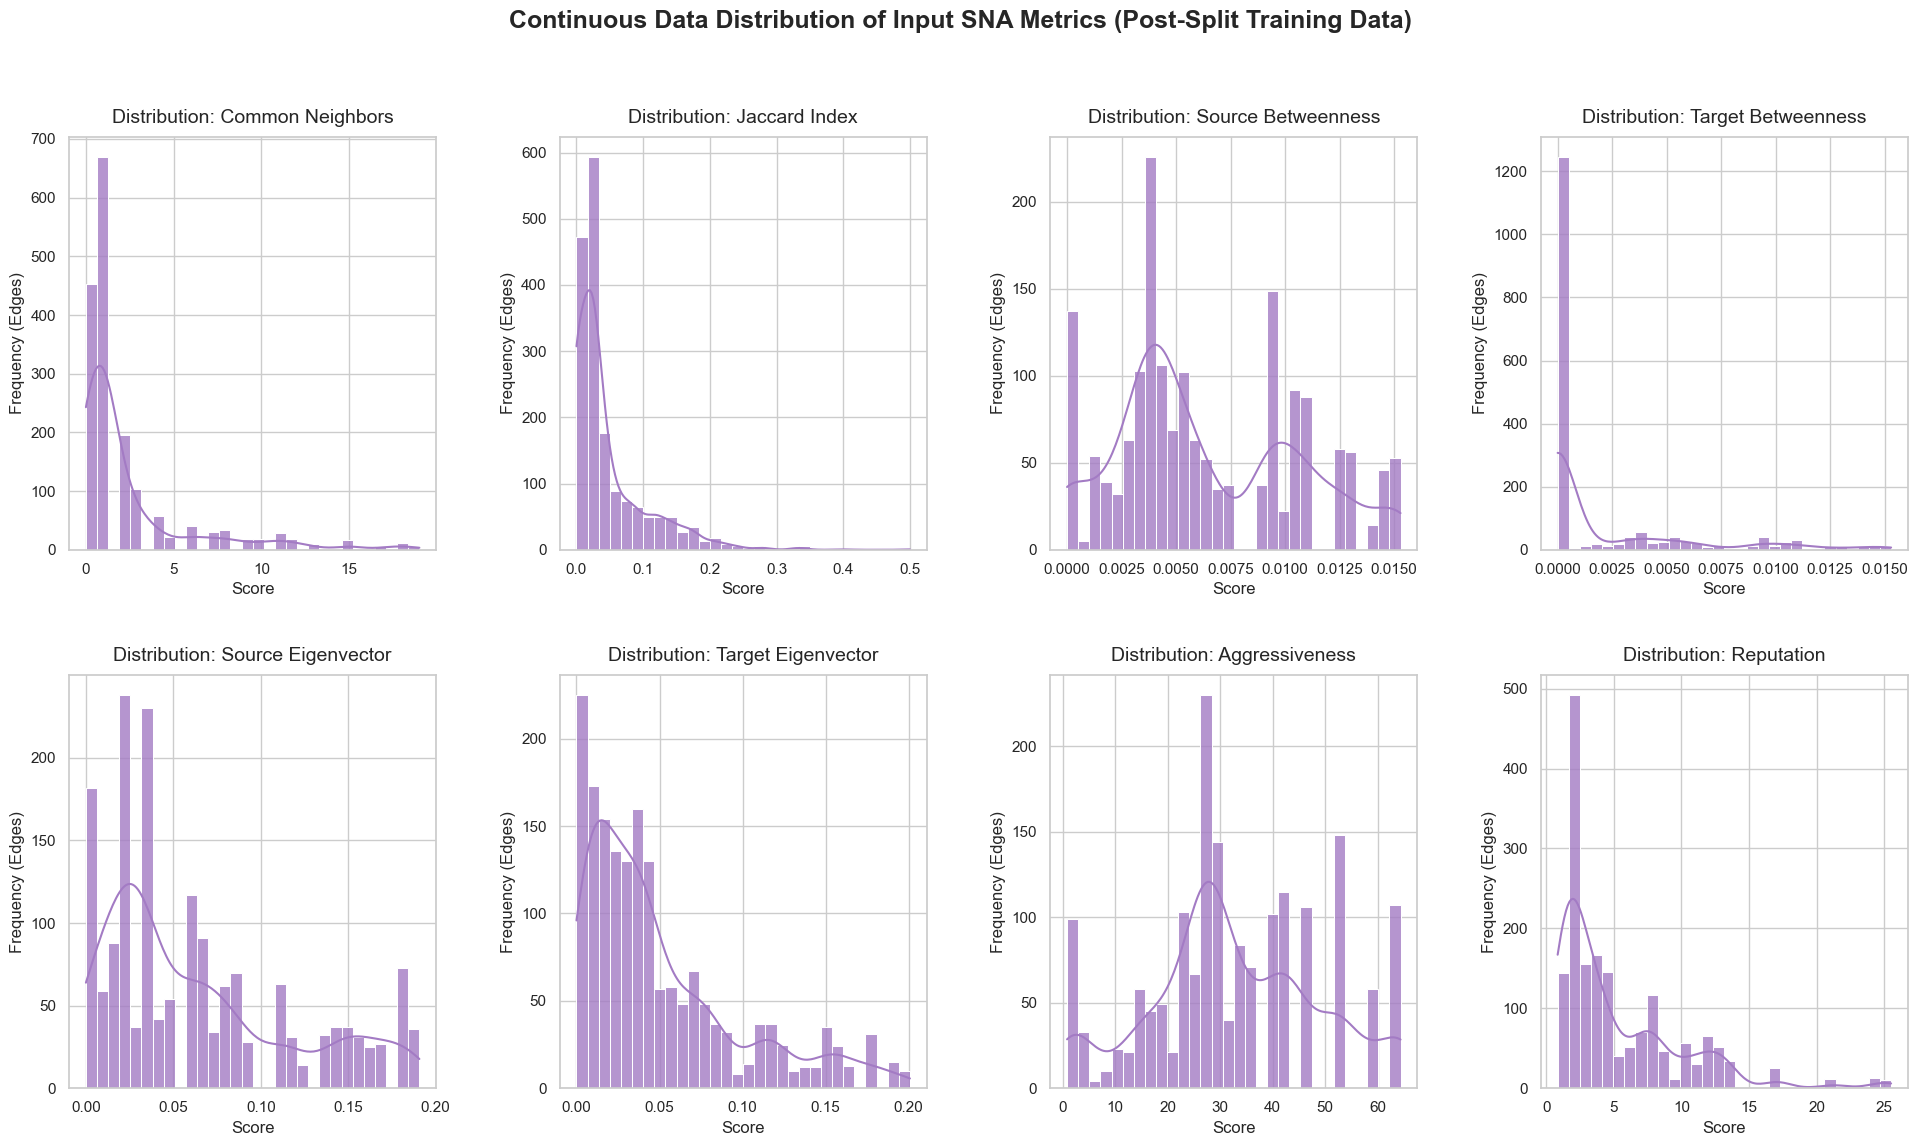

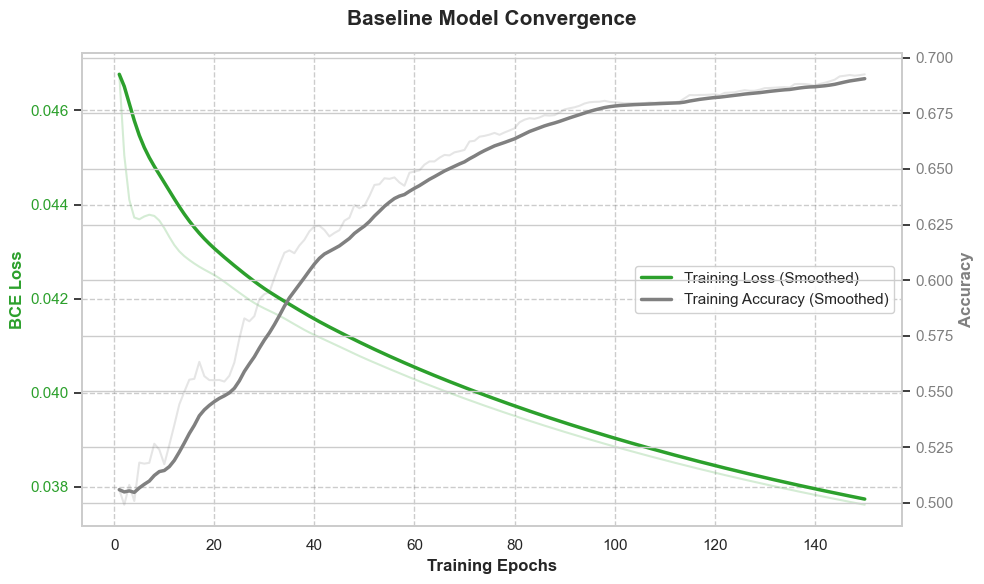

✅ Optimal Threshold Found: 0.520 (F1: 0.130)


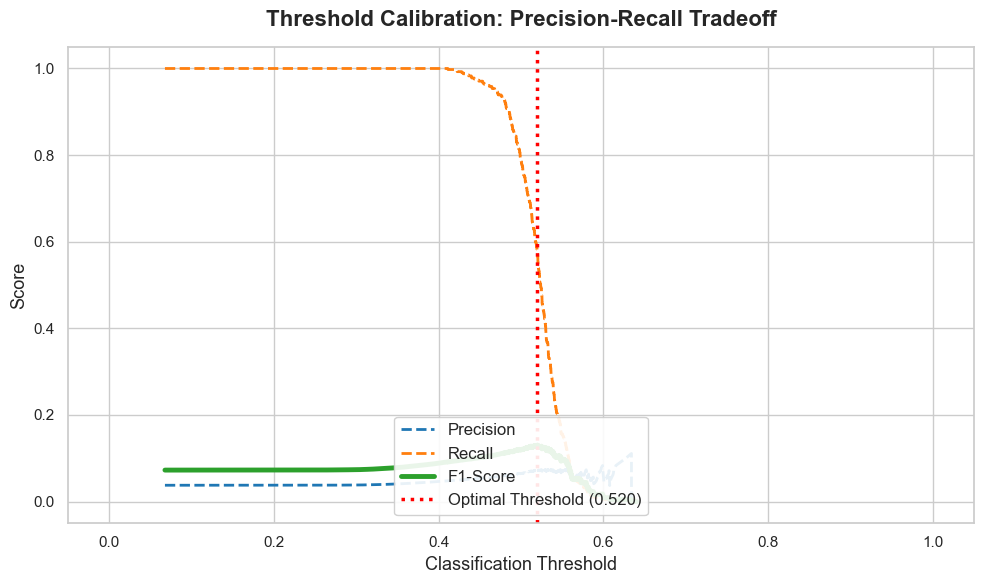

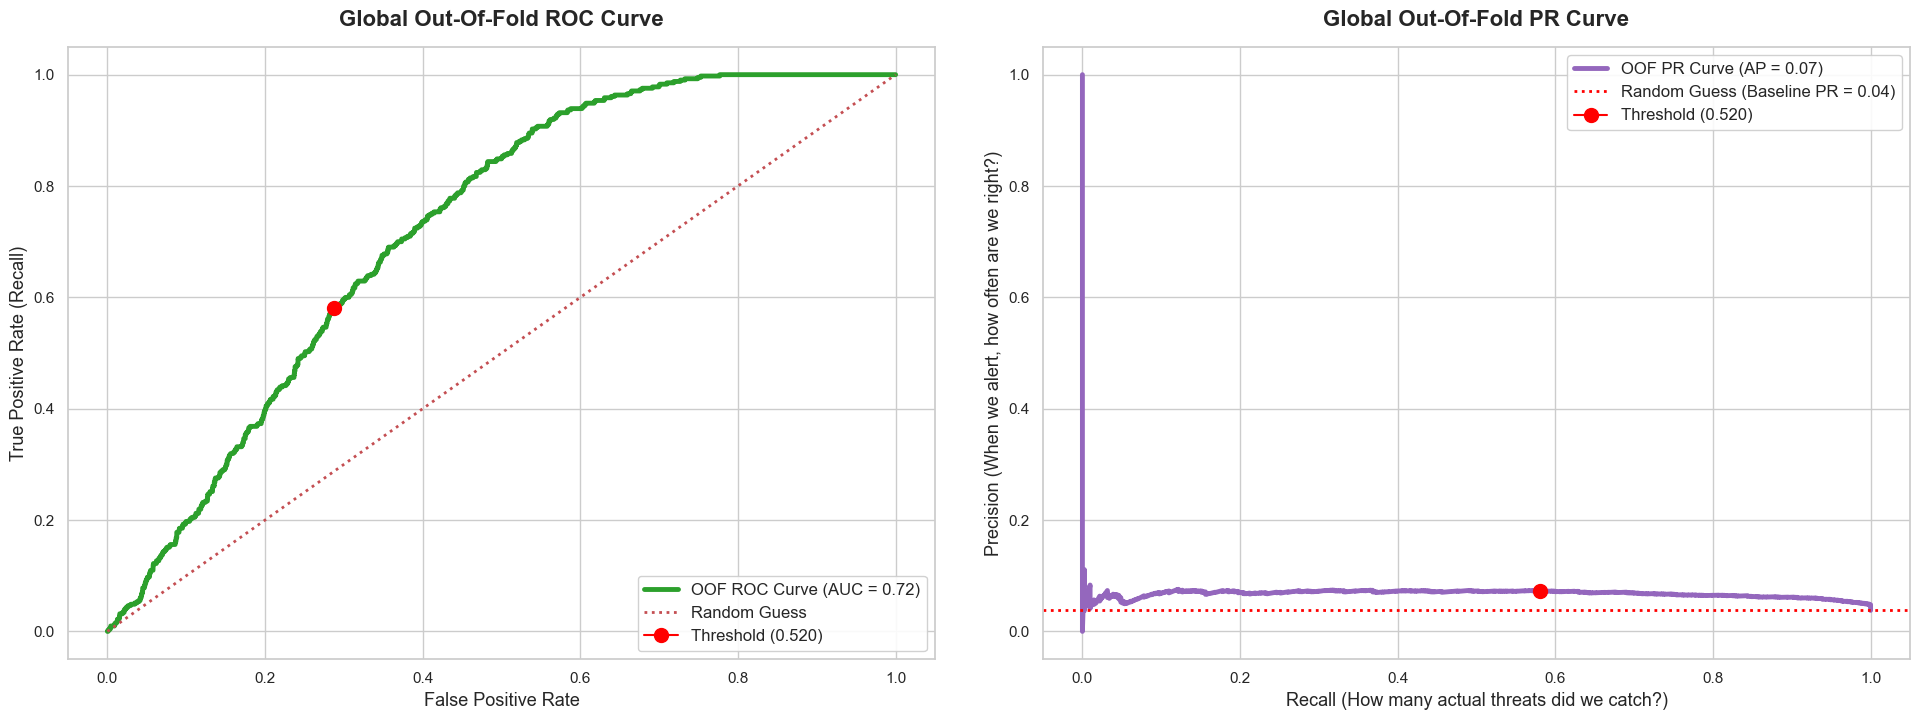

In [12]:
print("==========================================")
print(" CHAPTER 1: EVALUATING THE BASELINE MODEL ")
print("==========================================")

# 1. Initialize Baseline (edge_dim=6 for pure topology)
baseline_model = RiskEscalationGNN(
    num_node_features=data_baseline.x.size(1), 
    hidden_channels=64, 
    edge_dim=6  # <--- FIXED: Pure Topology only
)
# 2. Run the K-Fold
y_true_base, y_probs_base, histories_base = evaluate_with_kfold(
    baseline_model, 
    data_baseline, 
    n_splits=5, 
    epochs=150,
    is_enriched=False # <--- FIXED: Blinds the model to NLP weights
)

# 3. Plot Baseline Diagnostics
print("✅ Baseline Training Complete. Generating Diagnostics...")
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
fig_metric_dist = plot_dynamic_feature_distributions(data_baseline)
plt.savefig(f"{timestamp_dist}_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

fig_convergence = plot_model_convergence(histories_base, title="Baseline Model Convergence")
plt.savefig(f"{timestamp_dist}_convergence.png", dpi=300, bbox_inches='tight')
plt.show()

fig_thresh, opt_thresh_base = plot_threshold_calibration(y_true_base, y_probs_base)
plt.savefig(f"{timestamp_dist}_threshold_calibration.png", dpi=300, bbox_inches='tight')
plt.show()

fig_eval = plot_final_evaluation_curves(y_true_base, y_probs_base, opt_thresh_base)
plt.savefig(f"{timestamp_dist}_evaluation_dual.png", dpi=300, bbox_inches='tight')
plt.show()


## The enriched reality

 CHAPTER 2: TRAINING THE ENRICHED MODEL   
Epoch 000 | Loss: 0.0508 | Acc: 0.4898
Epoch 020 | Loss: 0.0405 | Acc: 0.6340
Epoch 040 | Loss: 0.0361 | Acc: 0.7500
Epoch 060 | Loss: 0.0329 | Acc: 0.7907
Epoch 080 | Loss: 0.0304 | Acc: 0.8215
Epoch 100 | Loss: 0.0285 | Acc: 0.8292
Epoch 120 | Loss: 0.0270 | Acc: 0.8322
Epoch 140 | Loss: 0.0258 | Acc: 0.8385
Epoch 000 | Loss: 0.0445 | Acc: 0.5236
Epoch 020 | Loss: 0.0393 | Acc: 0.6408
Epoch 040 | Loss: 0.0353 | Acc: 0.7301
Epoch 060 | Loss: 0.0324 | Acc: 0.7678
Epoch 080 | Loss: 0.0302 | Acc: 0.8183
Epoch 100 | Loss: 0.0284 | Acc: 0.8293
Epoch 120 | Loss: 0.0270 | Acc: 0.8395
Epoch 140 | Loss: 0.0258 | Acc: 0.8562
Epoch 000 | Loss: 0.0420 | Acc: 0.5879
Epoch 020 | Loss: 0.0369 | Acc: 0.7029
Epoch 040 | Loss: 0.0334 | Acc: 0.8027
Epoch 060 | Loss: 0.0310 | Acc: 0.8228
Epoch 080 | Loss: 0.0291 | Acc: 0.8201
Epoch 100 | Loss: 0.0277 | Acc: 0.8338
Epoch 120 | Loss: 0.0265 | Acc: 0.8464
Epoch 140 | Loss: 0.0256 | Acc: 0.8515
Epoch 000 | Loss: 0.0

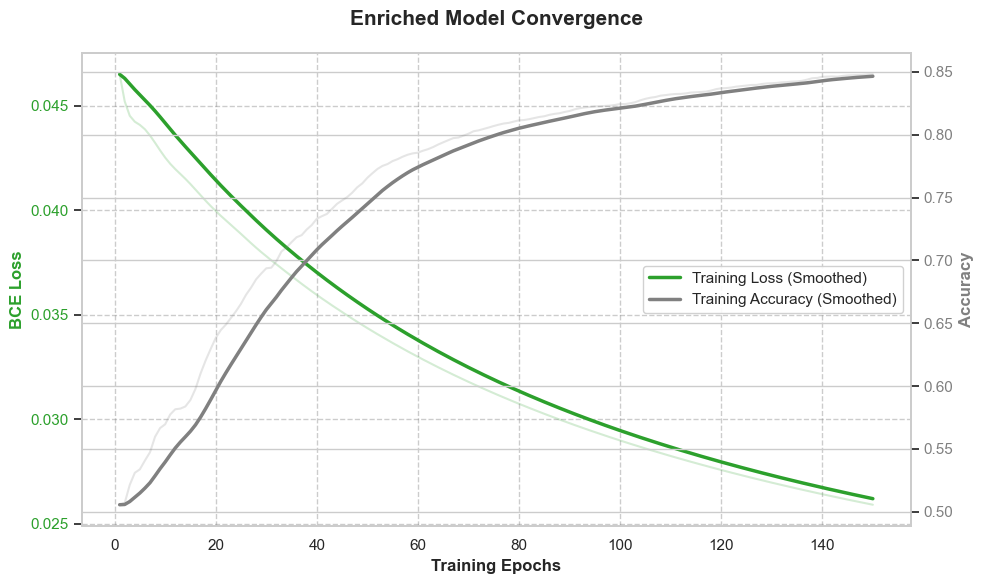

In [14]:
print("==========================================")
print(" CHAPTER 2: TRAINING THE ENRICHED MODEL   ")
print("==========================================")

# 1. Initialize Enriched (edge_dim=8 for Topology + Dynamic Aggressiveness/Reputation)
enriched_model = RiskEscalationGNN(
    num_node_features=data_enriched.x.size(1), 
    hidden_channels=64, 
    edge_dim=19  # <--- FIXED: 6 Topology + 2 NLP Edge Features
)

# 2. Run the K-Fold
y_true_enr, y_probs_enr, histories_enr = evaluate_with_kfold(
    enriched_model, 
    data_enriched, 
    n_splits=5, 
    epochs=150,
    is_enriched=True # <--- FIXED: Injects the LLM risk weights
)

print("✅ Enriched Training Complete. Generating Convergence...")
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
fig_conv_enr = plot_model_convergence(histories_enr, title="Enriched Model Convergence")
plt.savefig(f"{timestamp_dist}_convergence_enriched.png", dpi=300, bbox_inches='tight')
plt.show()

In [17]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

def compute_kfold_summary(y_true_folds, y_probs_folds, model_name="Model"):
    """
    Computes per-fold ROC-AUC and AP, then calculates Mean ± SD.
    Expects y_true_folds and y_probs_folds as lists of arrays (one per fold/repeat).
    """
    roc_list = []
    ap_list = []
    
    for fold_idx, (y_t, y_p) in enumerate(zip(y_true_folds, y_probs_folds)):
        roc_list.append(roc_auc_score(y_t, y_p))
        ap_list.append(average_precision_score(y_t, y_p))
        
    roc_mean, roc_sd = np.mean(roc_list), np.std(roc_list, ddof=1)
    ap_mean, ap_sd = np.mean(ap_list), np.std(ap_list, ddof=1)
    
    print(f"--- {model_name} (Over {len(roc_list)} Folds) ---")
    print(f"ROC-AUC: {roc_mean:.2f} ± {roc_sd:.2f}")
    print(f"AP:      {ap_mean:.2f} ± {ap_sd:.2f}\n")
    
    return {
        "roc_mean": roc_mean, "roc_sd": roc_sd,
        "ap_mean": ap_mean, "ap_sd": ap_sd
    }

# ==========================================================
# Run evaluation across folds if not already stored per-fold
# ==========================================================


# 1. Run Baseline (data_baseline loaded in Cell 2)
print("Evaluating Baseline Model across folds...")
res_base = evaluate_with_kfold(baseline_model, data_baseline, is_enriched=False)

# 2. Run Enriched Architecture (data_enriched loaded in Cell 2)
print("Evaluating Enriched GATv2 Model across folds...")
res_enriched = evaluate_with_kfold(enriched_model, data_enriched, is_enriched=True)

y_true_base = res_base[0]
y_probs_base = res_base[1]

y_true_enr = res_enriched[0]
y_probs_enr = res_enriched[1]

n_runs = 25

y_t_base_folds = np.array_split(y_true_base, n_runs)
y_p_base_folds = np.array_split(y_probs_base, n_runs)

y_t_enr_folds = np.array_split(y_true_enr, n_runs)
y_p_enr_folds = np.array_split(y_probs_enr, n_runs)

# 3. Calculate Mean ± SD
# Note: If evaluate_with_kfold returns (oof_y, oof_probs, histories, fold_splits),
# adapt keys/variables below to the per-fold test predictions:
stats_baseline = compute_kfold_summary(y_t_base_folds, y_p_base_folds, "Baseline")
stats_enriched = compute_kfold_summary(y_t_enr_folds, y_p_enr_folds, "Enriched GATv2 + Focal Loss")

# 4. Formatted Sentence for your Paper
sentence = (
    f"Under a leakage-controlled, repeated stratified k-fold protocol, "
    f"taxonomy-weighted, topology-enriched features raise the area under the ROC curve (ROC-AUC) "
    f"from {stats_baseline['roc_mean']:.2f} ± {stats_baseline['roc_sd']:.2f} to "
    f"{stats_enriched['roc_mean']:.2f} ± {stats_enriched['roc_sd']:.2f} and "
    f"average precision (AP) from {stats_baseline['ap_mean']:.2f} ± {stats_baseline['ap_sd']:.2f} to "
    f"{stats_enriched['ap_mean']:.2f} ± {stats_enriched['ap_sd']:.2f} "
    f"over an unweighted graph baseline."
)

print("Manuscript Sentence:")
print(sentence)

Evaluating Baseline Model across folds...
Epoch 000 | Loss: 0.0482 | Acc: 0.4456
Epoch 020 | Loss: 0.0448 | Acc: 0.4100
Epoch 040 | Loss: 0.0434 | Acc: 0.5197
Epoch 060 | Loss: 0.0422 | Acc: 0.5960
Epoch 080 | Loss: 0.0412 | Acc: 0.6124
Epoch 100 | Loss: 0.0404 | Acc: 0.6570
Epoch 120 | Loss: 0.0396 | Acc: 0.6615
Epoch 140 | Loss: 0.0389 | Acc: 0.6959
Epoch 160 | Loss: 0.0383 | Acc: 0.7150
Epoch 180 | Loss: 0.0377 | Acc: 0.7093
Epoch 200 | Loss: 0.0372 | Acc: 0.7105
Epoch 220 | Loss: 0.0368 | Acc: 0.7180
Epoch 240 | Loss: 0.0364 | Acc: 0.7084
Epoch 000 | Loss: 0.0422 | Acc: 0.5400
Epoch 020 | Loss: 0.0400 | Acc: 0.6273
Epoch 040 | Loss: 0.0390 | Acc: 0.6853
Epoch 060 | Loss: 0.0382 | Acc: 0.6844
Epoch 080 | Loss: 0.0375 | Acc: 0.6898
Epoch 100 | Loss: 0.0370 | Acc: 0.6910
Epoch 120 | Loss: 0.0367 | Acc: 0.6934
Epoch 140 | Loss: 0.0364 | Acc: 0.6868
Epoch 160 | Loss: 0.0361 | Acc: 0.6823
Epoch 180 | Loss: 0.0359 | Acc: 0.6829
Epoch 200 | Loss: 0.0358 | Acc: 0.6838
Epoch 220 | Loss: 0.03

## The final study

In [11]:
def plot_enriched_threshold_calibration(y_true_enr, y_probs_enr):
    """
    Plots the Threshold Calibration (Precision, Recall, F1) strictly for the Enriched model.
    """
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.set_theme(style="whitegrid")

    # --- Helper: Calculate Metrics safely ---
    def get_calibration_metrics(y_t, y_p):
        prec, rec, thresh = precision_recall_curve(y_t, y_p)
        f1 = np.divide(
            2 * (prec[:-1] * rec[:-1]), 
            (prec[:-1] + rec[:-1]),
            out=np.zeros_like(prec[:-1]), 
            where=(prec[:-1] + rec[:-1]) != 0
        )
        opt_idx = np.argmax(f1)
        return thresh, prec[:-1], rec[:-1], f1, thresh[opt_idx], f1[opt_idx]

    # Get data specifically for the Enriched model
    t_e, p_e, r_e, f1_e, opt_t_e, opt_f1_e = get_calibration_metrics(y_true_enr, y_probs_enr)

    # ==========================================
    # ENRICHED CALIBRATION PLOT (Purple Motif)
    # ==========================================
    ax.plot(t_e, p_e, '--', color='tab:blue', alpha=0.7, label='Precision', linewidth=2)
    ax.plot(t_e, r_e, '--', color='tab:orange', alpha=0.7, label='Recall', linewidth=2)

    # Using the purple aesthetic for the Enriched F1 curve
    ax.plot(t_e, f1_e, '-', color='#9467bd', label=f'Enriched F1-Score (Max: {opt_f1_e:.2f})', linewidth=3.5)

    # Red dotted line for the Optimal Threshold
    ax.axvline(opt_t_e, color='red', linestyle=':', linewidth=2.5, 
                label=f'Optimal Threshold ({opt_t_e:.3f})')

    ax.set_title('Enriched Model Calibration: Precision-Recall Tradeoff', fontsize=16, pad=15, fontweight='bold')
    ax.set_xlabel('Classification Threshold', fontsize=13)
    ax.set_ylabel('Score', fontsize=13)
    ax.set_xlim([-0.05, 1.05])
    ax.set_ylim([-0.05, 1.05])
    ax.legend(loc='lower center', fontsize=12, framealpha=0.9)

    plt.tight_layout()

    print(f"✅ Enriched Optimal Threshold Found: {opt_t_e:.3f} (F1: {opt_f1_e:.3f})")

    # We return the optimal threshold so you can use it in your final ablation plot!
    return fig, opt_t_e

In [12]:
def plot_ablation_evaluation(y_true_base, y_probs_base, opt_thresh_base, y_true_enr, y_probs_enr, opt_thresh_enr):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    sns.set_theme(style="whitegrid")

    print(f"📊 Using pre-calculated thresholds -> Baseline: {opt_thresh_base:.3f} | Enriched: {opt_thresh_enr:.3f}")
    # --- Smoothing Factor ---
    # Higher sigma = softer line. 2 to 3 is a good balance of smoothness without distorting reality.
    smooth_sigma = 2.5 

    # ==========================================
    # CHART 1: ROC CURVE COMPARISON
    # ==========================================
    # Baseline (Grey)
    fpr_b, tpr_b, _ = roc_curve(y_true_base, y_probs_base)
    roc_auc_b = auc(fpr_b, tpr_b)
    tpr_b_smooth = gaussian_filter1d(tpr_b, sigma=smooth_sigma) # Smooth the line
    ax1.plot(fpr_b, tpr_b_smooth, color='gray', linestyle='--', linewidth=2.5, 
             label=f'Baseline ROC (AUC = {roc_auc_b:.2f})')

    opt_fpr_b, opt_tpr_b, _ = roc_curve(y_true_base, y_probs_base >= opt_thresh_base)
    ax1.plot(opt_fpr_b[1], opt_tpr_b[1], marker='o', markersize=8, color='gray', markeredgecolor='black')

    # Enriched (Purple)
    fpr_e, tpr_e, _ = roc_curve(y_true_enr, y_probs_enr)
    roc_auc_e = auc(fpr_e, tpr_e)
    tpr_e_smooth = gaussian_filter1d(tpr_e, sigma=smooth_sigma) # Smooth the line
    ax1.plot(fpr_e, tpr_e_smooth, color='#2ca02c', linewidth=3.5, 
             label=f'Enriched ROC (AUC = {roc_auc_e:.2f})')

    opt_fpr_e, opt_tpr_e, _ = roc_curve(y_true_enr, y_probs_enr >= opt_thresh_enr)
    ax1.plot(opt_fpr_e[1], opt_tpr_e[1], marker='o', markersize=10, color='red', 
             label=f'Enriched Threshold ({opt_thresh_enr:.3f})')

    ax1.plot([0, 1], [0, 1], 'r:', linewidth=2, label='Random Guess')
    ax1.set_title('Ablation Study: ROC Curve Comparison', fontsize=16, fontweight='bold', pad=15)
    ax1.set_xlabel('False Positive Rate', fontsize=13)
    ax1.set_ylabel('True Positive Rate (Recall)', fontsize=13)
    ax1.legend(loc='lower right', fontsize=12, framealpha=0.9)

    # ==========================================
    # CHART 2: PR CURVE COMPARISON
    # ==========================================
    baseline_pr = np.mean(y_true_base) 

    # Baseline (Grey)
    prec_b, rec_b, _ = precision_recall_curve(y_true_base, y_probs_base)
    pr_auc_b = average_precision_score(y_true_base, y_probs_base)
    prec_b_smooth = gaussian_filter1d(prec_b, sigma=smooth_sigma) # Smooth the line
    ax2.plot(rec_b, prec_b_smooth, color='gray', linestyle='--', linewidth=2.5, 
             label=f'Baseline PR (AP = {pr_auc_b:.2f})')

    opt_p_b, opt_r_b, _ = precision_recall_curve(y_true_base, y_probs_base >= opt_thresh_base)
    ax2.plot(opt_r_b[1], opt_p_b[1], marker='o', markersize=8, color='gray', markeredgecolor='black')

    # Enriched (Purple)
    prec_e, rec_e, _ = precision_recall_curve(y_true_enr, y_probs_enr)
    pr_auc_e = average_precision_score(y_true_enr, y_probs_enr)
    prec_e_smooth = gaussian_filter1d(prec_e, sigma=smooth_sigma) # Smooth the line

    # Use drawstyle='steps-post' for a classic, clean PR curve look
    ax2.plot(rec_e, prec_e_smooth, color='#9467bd', linewidth=3.5, 
             label=f'Enriched PR (AP = {pr_auc_e:.2f})')

    opt_p_e, opt_r_e, _ = precision_recall_curve(y_true_enr, y_probs_enr >= opt_thresh_enr)
    ax2.plot(opt_r_e[1], opt_p_e[1], marker='o', markersize=10, color='red', 
             label=f'Enriched Threshold ({opt_thresh_enr:.3f})')

    ax2.axhline(baseline_pr, color='red', linestyle=':', linewidth=2, 
                label=f'Random Guess (AP = {baseline_pr:.2f})')

    ax2.set_title('Ablation Study: Precision-Recall Comparison', fontsize=16, fontweight='bold', pad=15)
    ax2.set_xlabel('Recall (How many actual threats did we catch?)', fontsize=13)
    ax2.set_ylabel('Precision (When we alert, how often are we right?)', fontsize=13)
    ax2.legend(loc='upper right', fontsize=12, framealpha=0.9)

    plt.tight_layout(pad=3.0)
    return fig

 CHAPTER 3: THE FINAL ABLATION STUDY      
✅ Enriched Optimal Threshold Found: 0.564 (F1: 0.447)


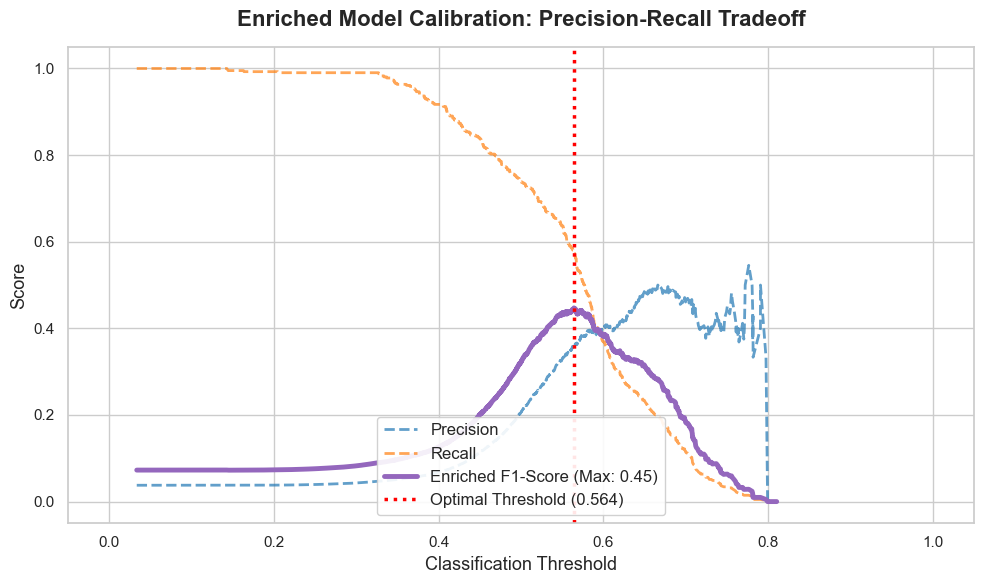

📊 Using pre-calculated thresholds -> Baseline: 0.520 | Enriched: 0.564


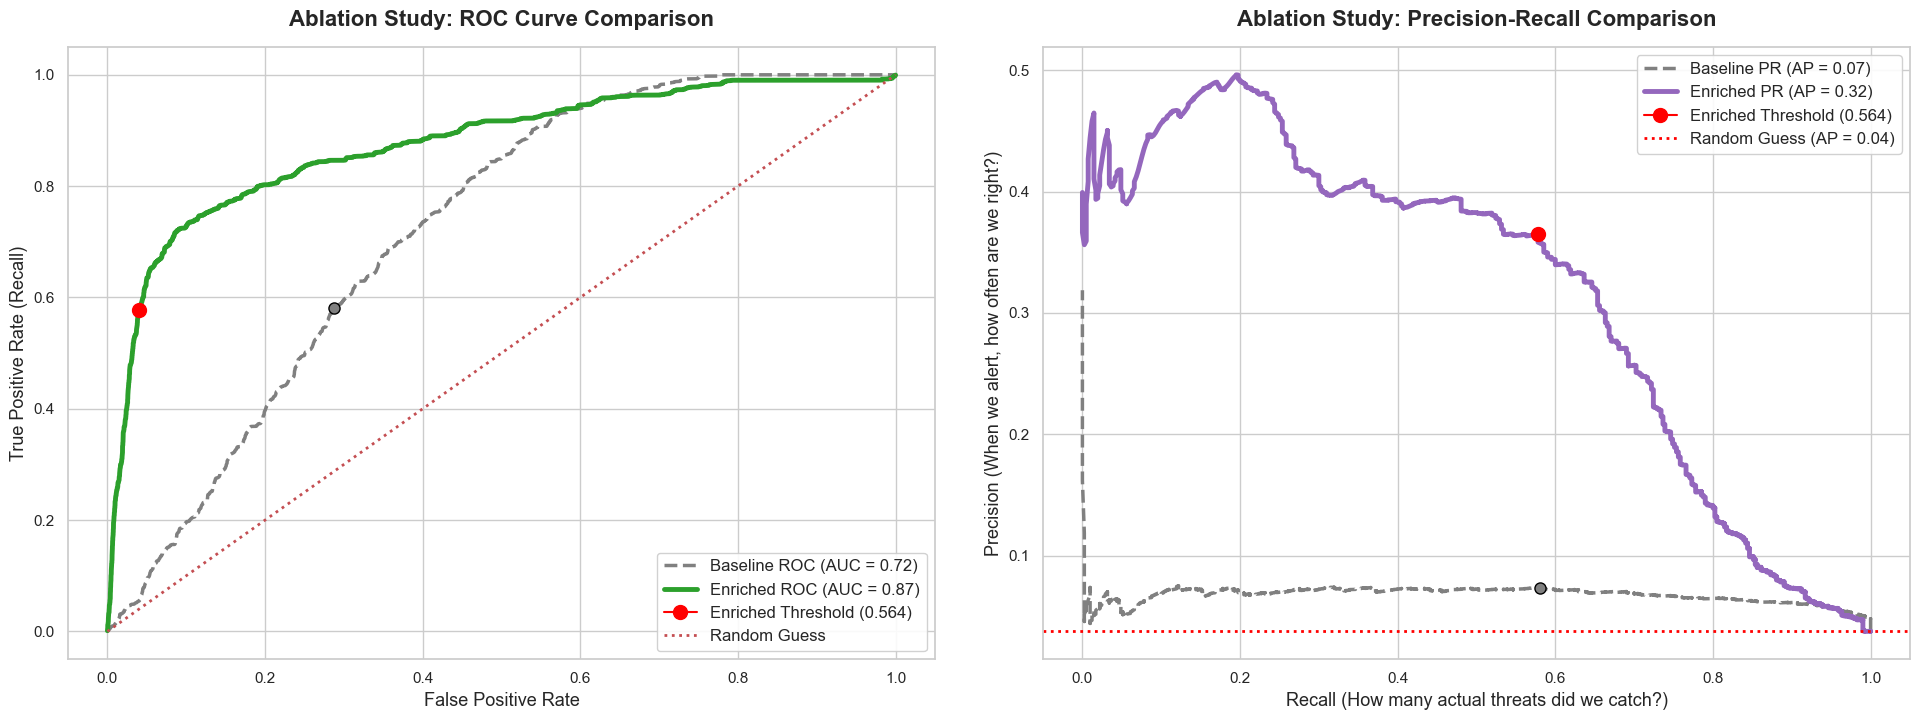

In [13]:
print("==========================================")
print(" CHAPTER 3: THE FINAL ABLATION STUDY      ")
print("==========================================")



#Plot the new Threshold Calibration Comparison!
fig_ablation_thresh, opt_thresh_enr = plot_enriched_threshold_calibration(y_true_enr, y_probs_enr)
plt.savefig(f"{timestamp_dist}_threshold_calibration_enriched.png", dpi=300, bbox_inches='tight')
plt.show()

fig_ablation = plot_ablation_evaluation(
    y_true_base, y_probs_base, opt_thresh_base, 
    y_true_enr, y_probs_enr, opt_thresh_enr
)

timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_final_ablation_study.png", dpi=300, bbox_inches='tight')
plt.show()

In [15]:
import pandas as pd

print("==========================================")
print(" DIAGNOSTIC HEALTH CHECK (PHASE 2 & 3) ")
print("==========================================")

# --- PHASE 2: PREDICTION SPREAD CHECK ---
print("\n--- PREDICTION SPREAD CHECK ---")
print("Baseline Prediction Stats:")
print(pd.Series(y_probs_base).describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]))
print("\nEnriched Prediction Stats:")
print(pd.Series(y_probs_enr).describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]))

# --- PHASE 3: TARGET IMBALANCE CHECK ---
print("\n--- TARGET IMBALANCE CHECK ---")
total_edges = len(data_enriched.y)
total_threats = int(data_enriched.y.sum().item())
print(f"Total Threats: {total_threats}")
print(f"Background Noise (Safe Edges): {total_edges - total_threats}")
print(f"Threat Ratio: {(total_threats / total_edges) * 100:.2f}%")



 DIAGNOSTIC HEALTH CHECK (PHASE 2 & 3) 

--- PREDICTION SPREAD CHECK ---
Baseline Prediction Stats:
count    10865.000000
mean         0.472438
std          0.071556
min          0.067707
25%          0.425317
50%          0.493554
75%          0.524999
90%          0.546018
99%          0.586740
max          0.640237
dtype: float64

Enriched Prediction Stats:
count    10865.000000
mean         0.403529
std          0.098455
min          0.033472
25%          0.340078
50%          0.402740
75%          0.457115
90%          0.523086
99%          0.695701
max          0.810459
dtype: float64

--- TARGET IMBALANCE CHECK ---
Total Threats: 82
Background Noise (Safe Edges): 2091
Threat Ratio: 3.77%


In [16]:

from IPython.display import display

print("==========================================")
print(" CHAPTER 4: ACTIONABLE RISK INTELLIGENCE  ")
print("==========================================")

print("🚀 Training final production model with full balance alignment...")

# 1. Initialize a fresh model
enriched_model = RiskEscalationGNN(num_node_features=1, hidden_channels=64, edge_dim=19)

# 2. Reconstruct the full 19-dimensional edge attributes
num_nodes_enr = data_enriched.x.size(0)
full_edge_attr_enr = calculate_strict_fold_topology(
    data_enriched.edge_index, 
    data_enriched.edge_index, 
    num_nodes_enr, 
    edge_weights=data_enriched.edge_weight
)
full_19d_edge_attr = torch.cat([full_edge_attr_enr, data_enriched.taxonomy], dim=1)

# 3. Create the full data object
final_imbalanced_data = Data(
    x=data_enriched.x,
    edge_index=data_enriched.edge_index,
    y=data_enriched.y,
    edge_attr=full_19d_edge_attr
)

# 4. 🛑 THE FIX: Balance the dataset so the model doesn't guess "Safe" for everyone!
final_balanced_data = graph_edge_oversample(final_imbalanced_data)

# 5. Train the final model
enriched_model, _ = train_model(enriched_model, final_balanced_data, epochs=250)


# 1. Generate the report using the mathematically optimal threshold
raw_threat_alerts = generate_threat_report(
    enriched_model, 
    data_enriched, 
    reverse_mapping,
    threshold=opt_thresh_enr,
    is_enriched=True
)

if not raw_threat_alerts:
    print(f"✅ No threats detected above the {opt_thresh_enr*100:.1f}% threshold. The facility is stable.")
else:
    # Build the DataFrame using the raw dictionary keys
    df_all_alerts = pd.DataFrame(raw_threat_alerts)[['source', 'target', 'probability']]

    # Deduplicate node pairs and grab the definitive Top 30 worst threats
    df_sorted = df_all_alerts.sort_values(by='probability', ascending=False)
    df_unique = df_sorted.drop_duplicates(subset=['source', 'target'], keep='first')
    df_top_30 = df_unique.head(20)

    # ------------------------------------------------======================
    # THE PARITY BRIDGE: Convert ONLY the top 30 back to a list of dicts!
    # This keeps your existing enrichment and drawing code completely intact,
    # but scales it down to run instantly for just those 30 rows.
    # ------------------------------------------------======================
    threat_alerts = df_top_30.to_dict('records')
    # ----------------------------------------------------------------======

    # Display your clean, styled Jupyter table (optional renaming just for viewing)
    df_display = df_top_30.copy()
    df_display.columns = ['Source Node', 'Target Node', 'Risk Score']
    # If your generate_threat_report doesn't multiply by 100, do it here:
    # df_display['Risk Score'] = df_display['Risk Score'] * 100 

    styled_table = df_display.style.background_gradient(
        subset=['Risk Score'], cmap='Reds', vmin=60.0, vmax=100.0
    ).format({'Risk Score': "{:.1f}%"}).set_caption(f"Top 20 Threat Escalations")

    timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
    df_display.to_csv(f"{timestamp_dist}"+"_report_risk.csv", index=False)

    display(styled_table)

 CHAPTER 4: ACTIONABLE RISK INTELLIGENCE  
🚀 Training final production model with full balance alignment...
Epoch 000 | Loss: 0.0471 | Acc: 0.4161
Epoch 020 | Loss: 0.0416 | Acc: 0.5414
Epoch 040 | Loss: 0.0375 | Acc: 0.7343
Epoch 060 | Loss: 0.0343 | Acc: 0.7951
Epoch 080 | Loss: 0.0319 | Acc: 0.8037
Epoch 100 | Loss: 0.0300 | Acc: 0.8087
Epoch 120 | Loss: 0.0285 | Acc: 0.8269
Epoch 140 | Loss: 0.0271 | Acc: 0.8343
Epoch 160 | Loss: 0.0260 | Acc: 0.8556
Epoch 180 | Loss: 0.0251 | Acc: 0.8577
Epoch 200 | Loss: 0.0242 | Acc: 0.8615
Epoch 220 | Loss: 0.0235 | Acc: 0.8668
Epoch 240 | Loss: 0.0229 | Acc: 0.8685


,Source Node,Target Node,Risk Score
0,Viper,Cruz,82.9%
1,Cruz,Jenkins,82.0%
2,Batista,Iron Syndicate,81.4%
3,Rossi,Iron Syndicate,80.8%
5,Mercer,Jenkins,80.4%
6,Viper,Iron Syndicate,79.7%
9,Rossi,Brooks,79.2%
11,Rollins,Jenkins,79.0%
12,Washington,Nash,78.5%
14,Kincaid,Washington,77.8%


🔍 Fetching semantic predicates and labels from Neo4j...


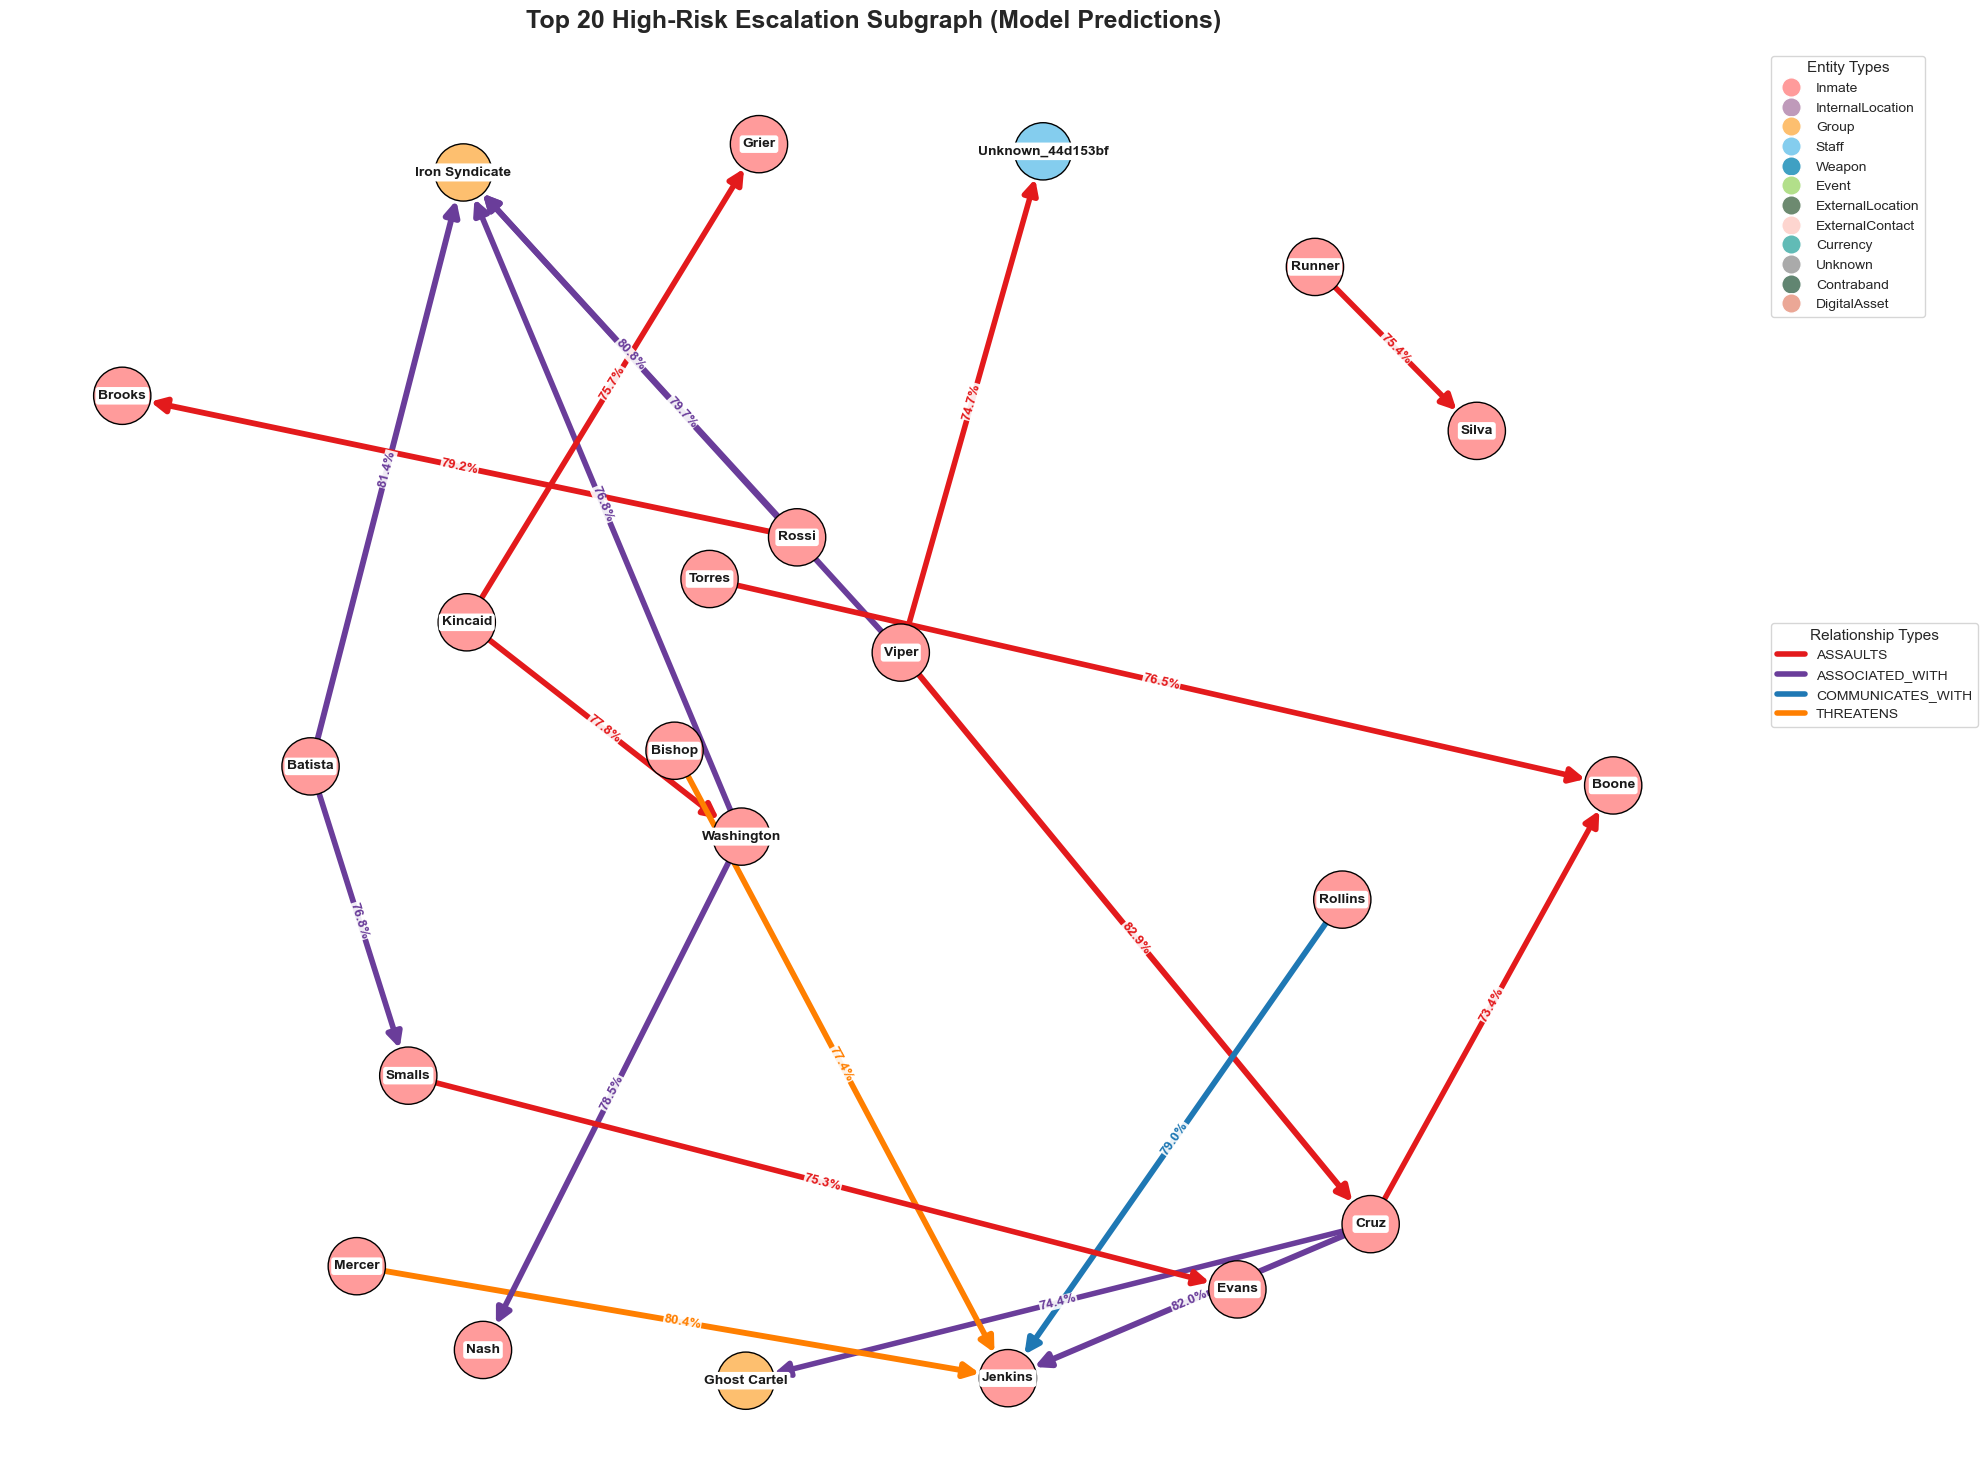

In [30]:
import networkx as nx
from matplotlib.lines import Line2D

# 1. Enrichment Function (Unchanged, it is working perfectly)
def enrich_alerts_with_predicates(alerts_list):
    print("🔍 Fetching semantic predicates and labels from Neo4j...")
    driver = GraphDatabase.driver(graph_base.URL, auth=(graph_base.USER, graph_base.PASS))

    with driver.session() as session:
        for alert in alerts_list:
            src = alert['source']
            tgt = alert['target']

            # Fetch the predicate AND the labels of the nodes
            query = """
            MATCH (a {name: $src})-[r]->(b {name: $tgt})
            WHERE type(r) <> 'SNA_TIE_STRENGTH'
            RETURN type(r) AS predicate, labels(a)[0] AS src_label, labels(b)[0] AS tgt_label LIMIT 1
            """
            result = session.run(query, src=src, tgt=tgt).single()

            if result:
                alert['predicate'] = result['predicate']
                alert['src_label'] = result['src_label'] # E.g., 'Inmate'
                alert['tgt_label'] = result['tgt_label'] # E.g., 'InternalLocation'

    driver.close()
    return alerts_list


# 2. Draw the Subgraph
if threat_alerts:
    threat_alerts = enrich_alerts_with_predicates(threat_alerts)
    G_threat = nx.DiGraph()

    color_map = {
        'Inmate': '#ff9b9b',
        'InternalLocation': '#bf9aba',
        'Group': '#fdbf6f',
        'Staff': '#84cdee',
        'Weapon': '#3fa0c3',
        'Event': '#b2df8a',
        'ExternalLocation': '#6d8a70',
        'ExternalContact': '#fdd5cf',
        'Currency': '#61bbb6',
        'Unknown': '#aaaaaa',
        'Contraband': '#618571',
        'DigitalAsset': '#eba796'
    }

    edge_color_map = {
        'ASSAULTS':  '#e31a1c',           # Strong Red
        'THREATENS': '#ff7f00',          # Orange
        'ASSOCIATED_WITH': '#6a3d9a',    # Purple
        'COMMUNICATES_WITH': '#1f78b4',  # Blue
        'AFFILIATED_WITH': '#b15928',    # Brown
        'EXCHANGES': '#33a02c',          # Green
        'POSSESSES': '#a6cee3',          # Light Blue
        'SELF_HARM': '#000000',          # Black
        'LOCATED_IN': '#b2df8a',         # Light Green
        'CONTAINS': '#fb9a99',           # Pink
        'DISTRIBUTES': '#fdbf6f',        # Light Orange
        'ESCALATES': '#4a1616'          # Fallback
    }

    for alert in threat_alerts:
        src = alert['source']
        tgt = alert['target']
        G_threat.add_node(src, label=alert.get('src_label', 'Inmate'))
        G_threat.add_node(tgt, label=alert.get('tgt_label', 'Inmate'))
        
        prob_val = alert['probability']
        prob_pct_string = f"{prob_val:.1f}%" if prob_val > 1.0 else f"{prob_val*100:.1f}%"
        normalized_weight = prob_val / 100.0 if prob_val > 1.0 else prob_val
        
        predicate = alert.get('predicate', 'ESCALATES')
        G_threat.add_edge(src, tgt, weight=normalized_weight, label=prob_pct_string, predicate=predicate)

    node_colors = [color_map.get(G_threat.nodes[n].get('label', 'Inmate'), '#cccccc') for n in G_threat.nodes()]

   # Canvas and Force configuration
    plt.figure(figsize=(20, 15)) 
    pos = nx.spring_layout(G_threat, k=3.0, iterations=200, seed=105)
    
    # ------------------------------------------------------------------
    # LAYER 1: DRAW THE ARROWS (Bottom Layer)
    # ------------------------------------------------------------------
    for idx, (u, v, data) in enumerate(G_threat.edges(data=True)):
        if G_threat.has_edge(v, u):
            edge_rad = 0.15  
        else:
            edge_rad = 0.0   
            
        edge_width = 1 + (data['weight'] * 4)

        pred = data.get('predicate', 'ESCALATES')
        e_color = edge_color_map.get(pred, '#808080') 
        
        nx.draw_networkx_edges(
            G_threat, pos, 
            edgelist=[(u, v)],
            arrowstyle='-|>', 
            arrowsize=22, 
            edge_color=e_color,     # <--- FIXED: Now uses the mapped color, not red!
            width=edge_width, 
            connectionstyle=f"arc3,rad={edge_rad}",
            node_size=1700
        ) 
        
    # ------------------------------------------------------------------
    # LAYER 2: DRAW THE NODES (Middle Layer)
    # ------------------------------------------------------------------
    # We draw the nodes NOW, so they cover the messy lines of the arrows,
    # but they do NOT cover the percentages yet.
    nx.draw_networkx_nodes(G_threat, pos, node_color=node_colors, edgecolors='black', node_size=1700, alpha=1.0)
    
    nx.draw_networkx_labels(
        G_threat, pos, font_size=10, font_weight='bold',
        bbox=dict(facecolor='white', edgecolor='none', alpha=1.0, boxstyle='round,pad=0.2')
    )

    # ------------------------------------------------------------------
    # LAYER 3: DRAW THE PERCENTAGES (Top Layer)
    # ------------------------------------------------------------------
    # Because this is the absolute last thing drawn, these percentages 
    # will stamp over EVERYTHING (lines, nodes, and borders).
    for idx, (u, v, data) in enumerate(G_threat.edges(data=True)):
        label_position = 0.35 if G_threat.has_edge(v, u) else 0.5
            
        pred = data.get('predicate', 'ESCALATES')
        e_color = edge_color_map.get(pred, '#808080') 
        
        nx.draw_networkx_edge_labels(
            G_threat, pos, 
            edge_labels={(u, v): data['label']}, 
            label_pos=label_position, 
            rotate=True,
            font_color=e_color, 
            font_size=9.5,      
            font_weight='bold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.9, pad=0.3) 
        )
    # ------------------------------------------------------------------

    # ------------------------------------------------------------------
    # DUAL LEGEND SETUP
    # ------------------------------------------------------------------
    ax = plt.gca()

    # Legend 1: Node Types (Top Right)
    node_legend_elements = [Line2D([0], [0], marker='o', color='w', label=k, markerfacecolor=v, markersize=14) for k, v in color_map.items()]
    legend1 = plt.legend(handles=node_legend_elements, bbox_to_anchor=(1.02, 1), loc='upper left', title="Entity Types", borderaxespad=0., fontsize=10, title_fontsize=11)
    ax.add_artist(legend1) # Add the first legend so it isn't overwritten

    # Legend 2: Edge Types (Middle Right)
    # Dynamically find which predicates are actually present in this specific subgraph to keep the legend clean
    used_predicates = sorted(set(nx.get_edge_attributes(G_threat, 'predicate').values()))
    edge_legend_elements = [Line2D([0], [0], color=edge_color_map.get(pred, '#808080'), lw=4, label=pred) for pred in used_predicates]
    plt.legend(handles=edge_legend_elements, bbox_to_anchor=(1.02, 0.6), loc='upper left', title="Relationship Types", borderaxespad=0., fontsize=10, title_fontsize=11)

    plt.title("Top 20 High-Risk Escalation Subgraph (Model Predictions)", fontsize=18, fontweight='bold', pad=20)
    plt.axis('off')

    # Ensure nothing gets clipped on execution
   
    timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
    plt.savefig(f"{timestamp_dist}_subgraph_risk.png", dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()

🔍 Fetching semantic predicates and labels from Neo4j...
✅ Louvain complete. Identified 6 strategic threat cells.


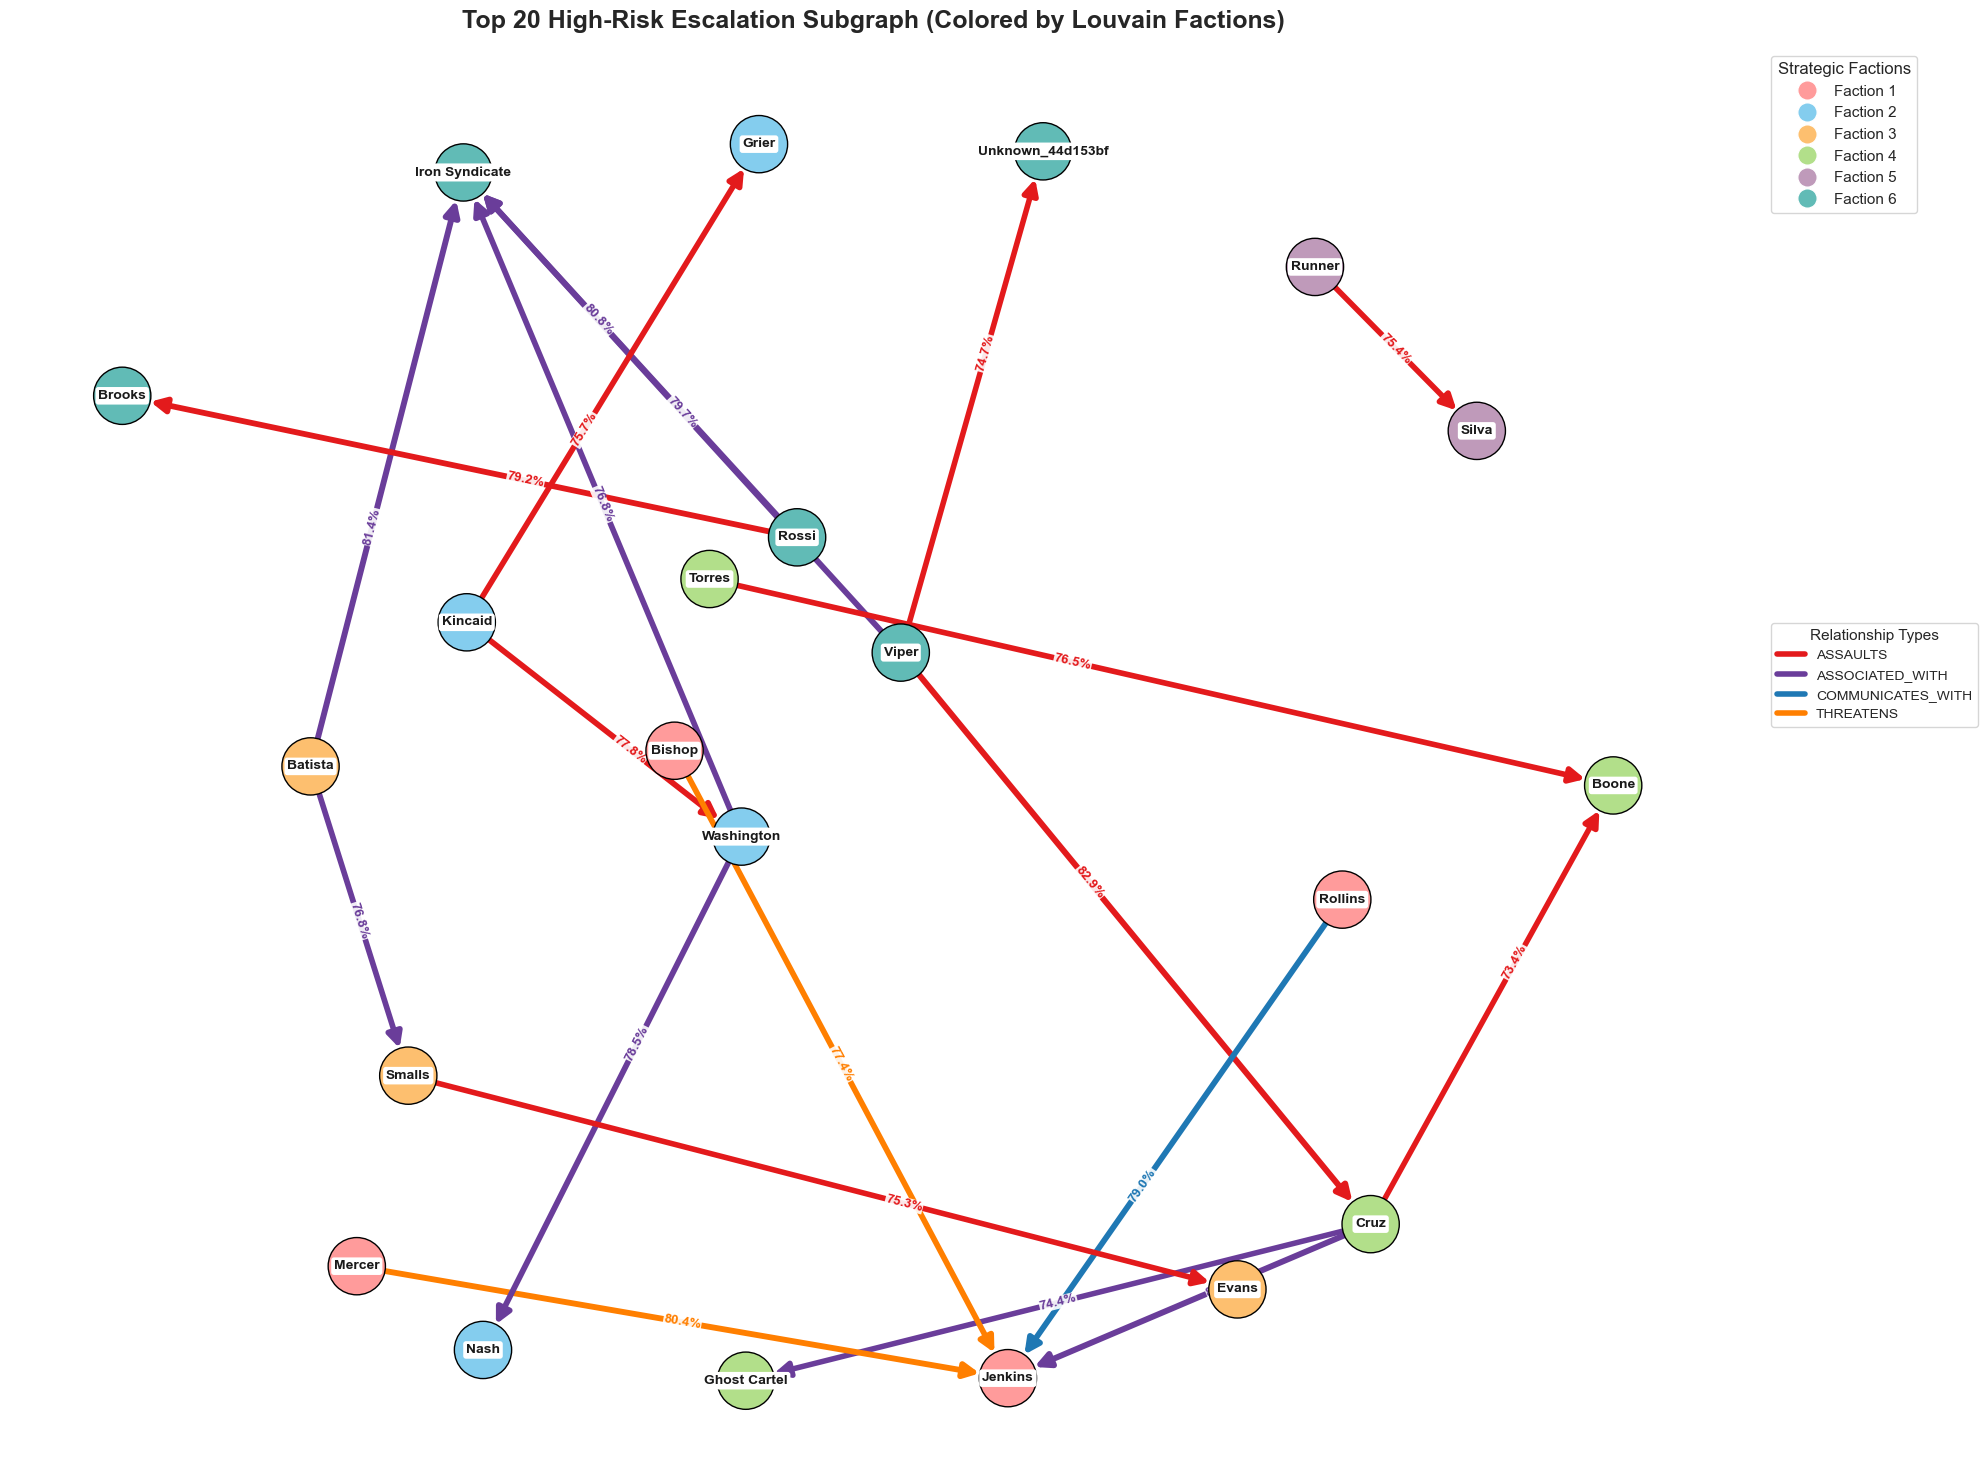

In [31]:
# 🛑 THE FIX: Import community algorithms through the correct internal pathway
from networkx.algorithms import community as nx_comm

if threat_alerts:
    # 1. Build the baseline directed graph
    threat_alerts = enrich_alerts_with_predicates(threat_alerts)
    G_threat = nx.DiGraph()
    
    # --- EDGE PREDICATE COLOR MAP ---
    edge_color_map = {
        'ASSAULTS': '#e31a1c',           
        'THREATENS': '#ff7f00',          
        'ASSOCIATED_WITH': '#6a3d9a',    
        'COMMUNICATES_WITH': '#1f78b4',  
        'AFFILIATED_WITH': '#b15928',    
        'EXCHANGES': '#33a02c',          
        'POSSESSES': '#a6cee3',          
        'SELF_HARM': '#000000',          
        'LOCATED_IN': '#b2df8a',         
        'CONTAINS': '#fb9a99',           
        'DISTRIBUTES': '#fdbf6f',        
        'ESCALATES': '#e31a1c'           
    }

    for alert in threat_alerts:
        src = alert['source']
        tgt = alert['target']
        G_threat.add_node(src, label=alert.get('src_label', 'Inmate'))
        G_threat.add_node(tgt, label=alert.get('tgt_label', 'Inmate'))

        prob_val = alert['probability']
        prob_pct_string = f"{prob_val:.1f}%" if prob_val > 1.0 else f"{prob_val*100:.1f}%"
        normalized_weight = prob_val / 100.0 if prob_val > 1.0 else prob_val

        predicate = alert.get('predicate', 'ESCALATES')
        
        # We only assign the percentage to the label to keep the graph clean
        G_threat.add_edge(src, tgt, weight=normalized_weight, label=prob_pct_string, predicate=predicate)

    # ==================================================================
    # 2. RUN LOUVAIN COMMUNITY DETECTION
    # ==================================================================
    G_undirected = G_threat.to_undirected()
    factions_list = nx_comm.louvain_communities(G_undirected, weight='weight', seed=42)

    # Map each node to its respective Faction ID string
    node_to_faction = {}
    for idx, faction_nodes in enumerate(factions_list):
        faction_name = f"Faction {idx + 1}"
        for node in faction_nodes:
            node_to_faction[node] = faction_name

    print(f"✅ Louvain complete. Identified {len(factions_list)} strategic threat cells.")

    # ==================================================================
    # 3. CONFIGURE FACTION COLOR PALETTE
    # ==================================================================
    # Soft, distinct qualitative colors for up to 6 factions
    faction_colors_pool = ['#ff9b9b', '#84cdee', '#fdbf6f', '#b2df8a', '#bf9aba', '#61bbb6']

    faction_color_map = {}
    for idx in range(len(factions_list)):
        faction_color_map[f"Faction {idx + 1}"] = faction_colors_pool[idx % len(faction_colors_pool)]

    # Assign node colors based on what faction they belong to
    node_colors = [faction_color_map[node_to_faction[n]] for n in G_threat.nodes()]

    # ==================================================================
    # 4. RENDER POLISHED SUBGRAPH VISUALIZATION
    # ==================================================================
    plt.figure(figsize=(20, 15)) 
    
    # Expanded physics layout to prevent node clumping
    pos = nx.spring_layout(G_threat, k=3.0, iterations=200, seed=105) 

    # ------------------------------------------------------------------
    # LAYER 1: DRAW THE ARROWS (Bottom Layer)
    # ------------------------------------------------------------------
    for idx, (u, v, data) in enumerate(G_threat.edges(data=True)):
        if G_threat.has_edge(v, u):
            edge_rad = 0.15 
        else:
            edge_rad = 0.0   

        edge_width = 1 + (data['weight'] * 4)
        
        pred = data.get('predicate', 'ESCALATES')
        e_color = edge_color_map.get(pred, '#808080')

        nx.draw_networkx_edges(
            G_threat, pos, edgelist=[(u, v)],
            arrowstyle='-|>', arrowsize=22, edge_color=e_color, 
            width=edge_width, connectionstyle=f"arc3,rad={edge_rad}",
            node_size=1700 # Forces arrows to touch the outside of the nodes!
        ) 

    # ------------------------------------------------------------------
    # LAYER 2: DRAW THE NODES (Middle Layer)
    # ------------------------------------------------------------------
    nx.draw_networkx_nodes(G_threat, pos, node_color=node_colors, edgecolors='black', node_size=1700, alpha=1.0)

    nx.draw_networkx_labels(
        G_threat, pos, font_size=10, font_weight='bold',
        bbox=dict(facecolor='white', edgecolor='none', alpha=1.0, boxstyle='round,pad=0.2')
    )
    
    # ------------------------------------------------------------------
    # LAYER 3: DRAW THE PERCENTAGES (Top Layer)
    # ------------------------------------------------------------------
    for idx, (u, v, data) in enumerate(G_threat.edges(data=True)):
        if G_threat.has_edge(v, u):
            label_position = 0.35 
        else:
            stagger_options = [0.4, 0.5, 0.6]
            label_position = stagger_options[idx % len(stagger_options)]
            
        pred = data.get('predicate', 'ESCALATES')
        e_color = edge_color_map.get(pred, '#808080') 
        
        nx.draw_networkx_edge_labels(
            G_threat, pos, edge_labels={(u, v): data['label']}, 
            label_pos=label_position, rotate=True,
            font_color=e_color, font_size=9.5, font_weight='bold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.9, pad=0.3)
        )

    # ------------------------------------------------------------------
    # DUAL LEGEND SETUP
    # ------------------------------------------------------------------
    ax = plt.gca()

    # Legend 1: Louvain Factions (Top Right)
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label=faction_id, markerfacecolor=color_hex, markersize=14) 
        for faction_id, color_hex in faction_color_map.items()
    ]
    legend1 = plt.legend(handles=legend_elements, bbox_to_anchor=(1.02, 1), loc='upper left', title="Strategic Factions", borderaxespad=0., fontsize=11, title_fontsize=12)
    ax.add_artist(legend1) 

    # Legend 2: Edge Types (Middle Right)
    used_predicates = sorted(set(nx.get_edge_attributes(G_threat, 'predicate').values()))
    edge_legend_elements = [Line2D([0], [0], color=edge_color_map.get(pred, '#808080'), lw=4, label=pred) for pred in used_predicates]
    plt.legend(handles=edge_legend_elements, bbox_to_anchor=(1.02, 0.6), loc='upper left', title="Relationship Types", borderaxespad=0., fontsize=10, title_fontsize=11)

    plt.title("Top 20 High-Risk Escalation Subgraph (Colored by Louvain Factions)", fontsize=18, fontweight='bold', pad=20)
    plt.axis('off')

    
    timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
    plt.savefig(f"{timestamp_dist}_subgraph_risk_louvain.png", dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()


In [19]:
print("📊 Calculating Table 3.6 SNA Metrics on the Predicted Threat Subgraph...")

# 1. Betweenness Centrality (Identifies the critical "Bridges/Smugglers")
# Uses the model's risk weights to see who controls the flow of threat paths
betweenness = nx.betweenness_centrality(G_threat, weight='weight')

# 2. Eigenvector Centrality (Identifies the "Bosses" / Most Influential Nodes)
# We use the numpy version because it is vastly more stable for directed, weighted graphs
try:
    eigenvector = nx.eigenvector_centrality_numpy(G_threat, weight='weight')
except Exception:
    # Fallback placeholder if the network structure doesn't converge
    eigenvector = {node: 0.0 for node in G_threat.nodes()}

# 3. Aggressiveness & Reputation (Relational Risk Metrics)
# According to your thesis: 
# Aggressiveness = Sum of outgoing risk weights (Out-Degree)
# Reputation/Vulnerability = Sum of incoming risk weights (In-Degree)
aggressiveness = {}
reputation = {}

for node in G_threat.nodes():
    # Sum up probabilities of all arrows leaving this node
    aggressiveness[node] = sum(weight for _, _, weight in G_threat.out_edges(node, data='weight', default=0.0))
    # Sum up probabilities of all arrows pointing to this node
    reputation[node] = sum(weight for _, _, weight in G_threat.in_edges(node, data='weight', default=0.0))

# ==================================================================
# 4. COMPILE THE MASTER THESIS RESULTS TABLE
# ==================================================================
analysis_records = []
for node in G_threat.nodes():
    analysis_records.append({
        "Entity Name": node,
        "Entity Type": G_threat.nodes[node].get('label', 'Inmate'),
        "Faction (Louvain)": node_to_faction.get(node, "Unassigned"), # Pulls from your Louvain run!
        "Aggressiveness (Outgoing Risk)": aggressiveness[node],
        "Reputation (Incoming Target Risk)": reputation[node],
        "Betweenness Centrality (Bridge)": betweenness[node],
        "Eigenvector Centrality (Influence)": eigenvector[node]
    })

# Convert to a beautiful DataFrame and sort by Influence
df_sna_results = pd.DataFrame(analysis_records)
df_sna_results = df_sna_results.sort_values(by="Eigenvector Centrality (Influence)", ascending=False).reset_index(drop=True)
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
df_sna_results.to_csv(f"{timestamp_dist}"+"_sna_metrics_result.csv", index=False)
# Format the floats cleanly for academic presentation
pd.set_option('display.float_format', lambda x: '%.4f' % x)
display(df_sna_results)

📊 Calculating Table 3.6 SNA Metrics on the Predicted Threat Subgraph...


,Entity Name,Entity Type,Faction (Louvain),Aggressiveness (Outgoing Risk),Reputation (Incoming Target Risk),Betweenness Centrality (Bridge),Eigenvector Centrality (Influence)
0,Viper,Inmate,Faction 6,2.3734,0.0000,0.0000,0.0000
1,Cruz,Inmate,Faction 4,2.2976,0.8288,0.0071,0.0000
2,Jenkins,Inmate,Faction 1,0.0000,3.1886,0.0000,0.0000
3,Batista,Inmate,Faction 3,1.5817,0.0000,0.0000,0.0000
4,Iron Syndicate,Group,Faction 6,0.0000,3.1872,0.0000,0.0000
5,Rossi,Inmate,Faction 6,1.5998,0.0000,0.0000,0.0000
6,Mercer,Inmate,Faction 1,0.8042,0.0000,0.0000,0.0000
7,Brooks,Inmate,Faction 6,0.0000,0.7920,0.0000,0.0000
8,Rollins,Inmate,Faction 1,0.7899,0.0000,0.0000,0.0000
9,Washington,Inmate,Faction 2,1.5531,0.7779,0.0048,0.0000


In [ ]:
import numpy as np
import torch

print("==========================================")
print(" THE FINAL SANITY CHECK: EXTREME EDGES ")
print("==========================================")

# 1. Reconstruct the exact 19-dimensional feature space for the model
num_nodes = data_enriched.x.size(0)
full_topo = calculate_strict_fold_topology(
    data_enriched.edge_index, 
    data_enriched.edge_index, 
    num_nodes, 
    edge_weights=data_enriched.edge_weight
)
full_19d_attr = torch.cat([full_topo, data_enriched.taxonomy], dim=1)

# 2. Ask the final model to predict on the 920 edges using the 19D tensor
enriched_model.eval()
with torch.no_grad():
    logits = enriched_model(data_enriched.x, data_enriched.edge_index, full_19d_attr)
    final_probs = torch.sigmoid(logits).cpu().numpy().flatten()

# 3. Invert your taxonomy dictionary so we can read the names in plain English
taxonomy_mapping = {
    'AFFILIATED_WITH': 0, 'ASSAULTS': 1, 'ASSOCIATED_WITH': 2, 
    'COMMUNICATES_WITH': 3, 'CONTAINS': 4, 'DISTRIBUTES': 5, 
    'EXCHANGES': 6, 'LOCATED_IN': 7, 'POSSESSES': 8, 
    'SELF_HARM': 9, 'THREATENS': 10
}
reverse_tax = {v: k for k, v in taxonomy_mapping.items()}

# 4. Find the exact indices of the highest and lowest predictions
max_idx = np.argmax(final_probs)
min_idx = np.argmin(final_probs)

def print_edge_profile(idx, title):
    src_id = data_enriched.edge_index[0][idx].item()
    tgt_id = data_enriched.edge_index[1][idx].item()
    src_name = reverse_mapping[src_id]
    tgt_name = reverse_mapping[tgt_id]
    
    prob = final_probs[idx]
    
    # Extract raw structural stats from our newly built tensor
    cn, jac, aa = full_19d_attr[idx][:3].tolist()
    
    # Safely pull the taxonomy vector directly from the dataset
    tax_vector = data_enriched.taxonomy[idx].tolist()
    behavior = "NO KNOWN BEHAVIOR (All Zeros)"
    if 1.0 in tax_vector:
        behavior = reverse_tax[tax_vector.index(1.0)]
        
    print(f"\n{title}")
    print(f"Edge: {src_name} ➔ {tgt_name}")
    print(f"Risk Prediction: {prob*100:.2f}%")
    print(f"Structural Metrics: Common Neighbors = {cn:.1f}, Jaccard = {jac:.3f}")
    print(f"Behavior Trigger: {behavior}")

print_edge_profile(max_idx, "🔥 THE MOST DANGEROUS EDGE (Top Prediction) 🔥")
print_edge_profile(min_idx, "🧊 THE SAFEST EDGE (Bottom Prediction) 🧊")